<a href="https://colab.research.google.com/github/DengAchiek/Sudo-tasks/blob/main/Road_Safety_in_Nairobi_Starter_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Road Safety in Nairobi Capstone Analysis

---



---



**Purpose:** Explore historical crash data, identify spatial and temporal patterns, investigate crash severity, and prepare for emergency-response optimization.

This notebook is a starting framework. It does not assume that the dataset has particular column names or that every proposed analysis is possible with the currently available data.

**Research questions**
1. Where are the crash hotspots in Nairobi?
2. When do crashes happen (hour, day, month, and rainfall conditions)?
3. Which factors are associated with more serious crashes?
4. Where should ambulances be stationed?
5. What is the fastest, safest route to a crash?

**Important:** A crash-only dataset can describe reported crashes, but cannot by itself estimate the probability of a crash occurring on every road segment/time period. Reliable occurrence prediction needs suitable non-crash observations or exposure data. Likewise, route optimization requires a routable road network and credible travel-time/risk weights.


## 1. Environment setup

In [1]:
# Run this cell if the required packages are not installed.
# In a terminal, you can also run:
# pip install pandas numpy matplotlib seaborn plotly scikit-learn scipy geopandas contextily

import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
warnings.filterwarnings("ignore")

print("Python:", sys.version)
print("Pandas:", pd.__version__)


Python: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Pandas: 2.2.3


## 2. Set project paths and identify the input files

The three uploaded CSV files are related Victorian road-crash tables. Keep them together in the notebook's `data` folder when working locally.

**Important geographic note:** These files describe road crashes in Victoria, Australia, not Nairobi, Kenya. They are useful for practising the workflow and building/test-driving code, but they must not be presented as Nairobi evidence. Replace them with the approved Nairobi dataset before drawing conclusions about Nairobi.

In [2]:

from pathlib import Path
import pandas as pd

PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "data"
OUTPUT_DIR = PROJECT_DIR / "outputs"

OUTPUT_DIR.mkdir(exist_ok=True)

# Dataset file paths (Google Colab)
FILE_PATHS = {
    "accident": Path("/content/_published_safety_victoria_road_crash_data_ACCIDENT.csv"),
    "accident_event": Path("/content/_published_safety_victoria_road_crash_data_ACCIDENT_EVENT.csv"),
    "accident_location": Path("/content/_published_safety_victoria_road_crash_data_ACCIDENT_LOCATION.csv"),
    "atmospheric_cond": Path("/content/_published_safety_victoria_road_crash_data_ATMOSPHERIC_COND.csv"),
    "node": Path("/content/_published_safety_victoria_road_crash_data_NODE.csv"),
    "person": Path("/content/_published_safety_victoria_road_crash_data_PERSON.csv"),
    "road_surface_cond": Path("/content/_published_safety_victoria_road_crash_data_ROAD_SURFACE_COND.csv"),
    "vehicle": Path("/content/_published_safety_victoria_road_crash_data_VEHICLE.csv"),
    "victorian_road_crash_data": Path("/content/_published_safety_victoria_road_crash_data_VICTORIAN_ROAD_CRASH_DATA.csv")
}

# Uploaded files
SESSION_FILE_PATHS = {
    "accident": Path("/mnt/data/_published_safety_victoria_road_crash_data_ACCIDENT.csv"),
    "accident_event": Path("/mnt/data/_published_safety_victoria_road_crash_data_ACCIDENT_EVENT.csv"),
    "accident_location": Path("/mnt/data/_published_safety_victoria_road_crash_data_ACCIDENT_LOCATION.csv"),
    "atmospheric_cond": Path("/mnt/data/_published_safety_victoria_road_crash_data_ATMOSPHERIC_COND.csv"),
    "node": Path("/mnt/data/_published_safety_victoria_road_crash_data_NODE.csv"),
    "person": Path("/mnt/data/_published_safety_victoria_road_crash_data_PERSON.csv"),
    "road_surface_cond": Path("/mnt/data/_published_safety_victoria_road_crash_data_ROAD_SURFACE_COND.csv"),
    "vehicle": Path("/mnt/data/_published_safety_victoria_road_crash_data_VEHICLE.csv"),
    "victorian_road_crash_data": Path("/mnt/data/_published_safety_victoria_road_crash_data_VICTORIAN_ROAD_CRASH_DATA.csv")
}

print("Project folder:", PROJECT_DIR.resolve())
print("Data folder:", DATA_DIR.resolve())


Project folder: /content
Data folder: /content/data


## 3. Load all three related CSV files

`ACCIDENT` is the main crash-level table. `ACCIDENT_EVENT` contains event-level details, and `ACCIDENT_LOCATION` contains road/location descriptions. The tables share identifiers such as `ACCIDENT_NO`; inspect key uniqueness before joining because the event table may contain multiple rows per crash.

In [3]:

def resolve_file(local_path, session_path):
    if local_path.exists():
        return local_path
    elif session_path.exists():
        return session_path
    else:
        print(f"File not found: {local_path.name}")
        return None


data = {}

for name in FILE_PATHS:
    path = resolve_file(
        FILE_PATHS[name],
        SESSION_FILE_PATHS[name]
    )

    if path is not None:
        data[name] = pd.read_csv(path, low_memory=False)
        print(f"{name}: {data[name].shape}")

print("\nSuccessfully loaded:", len(data), "datasets")


accident: (202554, 23)
accident_event: (332516, 13)
accident_location: (202554, 9)
atmospheric_cond: (205129, 4)
node: (407972, 11)
person: (473007, 14)
road_surface_cond: (203632, 4)
vehicle: (369699, 37)
victorian_road_crash_data: (202554, 52)

Successfully loaded: 9 datasets


In [4]:
data["accident"]
data["accident_event"]
data["accident_location"]
data["atmospheric_cond"]
data["node"]
data["person"]
data["road_surface_cond"]
data["vehicle"]
data["victorian_road_crash_data"]

,ACCIDENT_NO,ACCIDENT_DATE,ACCIDENT_TIME,ACCIDENT_TYPE,DAY_OF_WEEK,DCA_CODE,DCA_CODE_DESCRIPTION,LIGHT_CONDITION,POLICE_ATTEND,ROAD_GEOMETRY,SEVERITY,SPEED_ZONE,RUN_OFFROAD,ROAD_NAME,ROAD_TYPE,ROAD_ROUTE_1,LGA_NAME,DTP_REGION,LATITUDE,LONGITUDE,VICGRID_X,VICGRID_Y,TOTAL_PERSONS,INJ_OR_FATAL,FATALITY,SERIOUSINJURY,OTHERINJURY,NONINJURED,MALES,FEMALES,BICYCLIST,PASSENGER,DRIVER,PEDESTRIAN,PILLION,MOTORCYCLIST,UNKNOWN,PED_CYCLIST_5_12,PED_CYCLIST_13_18,OLD_PED_65_AND_OVER,OLD_DRIVER_75_AND_OVER,YOUNG_DRIVER_18_25,NO_OF_VEHICLES,HEAVYVEHICLE,PASSENGERVEHICLE,MOTORCYCLE,PT_VEHICLE,DEG_URBAN_NAME,SRNS,RMA,DIVIDED,STAT_DIV_NAME
0,T20140024624,2014-11-27,18:35:00,Collision with vehicle,Thursday,110,CROSS TRAFFIC(INTERSECTIONS ONLY),Day,Yes,Cross intersection,Other injury accident,50 km/hr,No,ALFRED,STREET,9999.0,WELLINGTON,GIPPSLAND,-37.961970,146.98431,2674362.051,2391427.834,3,1,0,0,1,2,3,0,0,1,2,0,0,0,0,0,0,0,0,1,2.0,0.0,2.0,0.0,0.0,TOWNS,NaN,Local Road,Undivided,Country
1,T20190026336,2019-12-27,15:45:00,Collision with vehicle,Friday,113,RIGHT NEAR (INTERSECTIONS ONLY),Day,Yes,T intersection,Other injury accident,60 km/hr,No,WATERDALE,ROAD,5744.0,BANYULE,INNER METRO,-37.748672,145.04663,2504109.105,2416918.267,3,1,0,0,1,2,2,1,0,1,2,0,0,0,0,0,0,0,0,0,2.0,0.0,2.0,0.0,0.0,MELB_URBAN,NaN,Arterial Other,Divided,Metro
2,T20190019196,2019-10-02,12:07:00,Collision with vehicle,Wednesday,173,RIGHT OFF CARRIAGEWAY INTO OBJECT/PARKED VEHICLE,Day,Yes,Not at intersection,Other injury accident,100 km/hr,Yes,WESTERN RING,ROAD,2900.0,BRIMBANK,INNER METRO,-37.728622,144.85841,2487518.843,2419134.905,5,1,0,0,1,4,1,4,0,2,3,0,0,0,0,0,0,0,0,0,3.0,0.0,2.0,0.0,0.0,MELB_URBAN,M,Freeway,Divided,Metro
3,T20250029202,2025-11-07,13:10:00,Struck Pedestrian,Friday,100,PED NEAR SIDE. PED HIT BY VEHICLE FROM THE RIGHT.,Day,Yes,Not at intersection,Serious injury accident,80 km/hr,No,DANDENONG VALLEY,HIGHWAY,2090.0,KNOX,GREATER METRO,-37.926075,145.23350,2520529.530,2397204.370,2,1,0,1,0,1,2,0,0,0,1,1,0,0,0,0,0,0,0,1,1.0,0.0,1.0,0.0,0.0,MELB_URBAN,NaN,Arterial Highway,Divided,Metro
4,T20210005363,2021-01-30,06:30:00,Collision with a fixed object,Saturday,183,OFF LEFT BEND INTO OBJECT/PARKED VEHICLE,Dusk/Dawn,No,Not at intersection,Serious injury accident,80 km/hr,Yes,GEMBROOK-LAUNCHING PLACE,ROAD,5522.0,CARDINIA,GREATER METRO,-37.905216,145.59479,2552306.747,2399380.957,1,1,0,1,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,1,1.0,0.0,1.0,0.0,0.0,RURAL_VICTORIA,C,Arterial Other,Undivided,Metro
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
202549,T20250029781,2025-11-12,15:20:00.0000000,Collision with vehicle,Wednesday,110,CROSS TRAFFIC(INTERSECTIONS ONLY),Day,Yes,Unknown,Other injury accident,80 km/hr,No,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,1,0,0,1,1,1,1,0,0,2,0,0,0,0,0,0,0,0,1,2.0,0.0,2.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN
202550,T20190006335,2018-12-07,03:54:00.0000000,Collision with a fixed object,Friday,179,OTHER ACCIDENTS-OFF STRAIGHT NOT INCLUDED IN D...,Unk.,No,Unknown,Other injury accident,Not known,No,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,1,0,0,1,0,1,0,0,0,0,0,0,0,2,0,0,0,0,0,1.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN
202551,T20250031997,2025-12-05,12:28:00.0000000,Struck Pedestrian,Friday,108,PED STRUCK WALKING TO/FROM OR BOARDING/ALIGHTI...,Day,No,Unknown,Other injury accident,50 km/hr,No,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,1,0,0,1,1,2,0,0,1,1,0,0,0,0,0,0,0,0,0,1.0,0.0,1.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN
202552,T20250025055,2025-09-21,19:52:00.0000000,Collision with vehicle,Sunday,110,CROSS TRAFFIC(INTERSECTIONS ONLY),Dark Street lights on,Yes,Unknown,Other injury accident,60 km/hr,No,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3,3,0,0,3,0,1,2,0,1,2,0,0,0,0,0,0,0,0,1,2.0,0.0,2.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN


## 4. Inspect the three tables and their relationships

In [5]:

# Inspect all datasets
for name, df in data.items():
    print(f"\n{name.upper()}")

    # Preview records
    display(df.head())

    # Column names
    print("\nColumns:")
    print(df.columns.tolist())

    # Missing-value analysis
    missing = df.isna().sum().sort_values(ascending=False)

    missing_summary = pd.DataFrame({
        "missing_count": missing,
        "missing_percentage": (missing / len(df) * 100).round(2)
    })

    print("\nTop 15 columns with missing values:")
    display(missing_summary.head(15))


# Check ACCIDENT_NO uniqueness
print("\n CRASH ID CHECK ")

for name, df in data.items():
    if "ACCIDENT_NO" in df.columns:
        unique_ids = df["ACCIDENT_NO"].nunique()
        duplicate_rows = df["ACCIDENT_NO"].duplicated().sum()

        print(
            f"{name}: "
            f"unique crash IDs = {unique_ids:,}; "
            f"rows = {len(df):,}; "
            f"duplicate crash-ID rows = {duplicate_rows:,}"
        )



ACCIDENT


,ACCIDENT_NO,ACCIDENT_DATE,ACCIDENT_TIME,ACCIDENT_TYPE,ACCIDENT_TYPE_DESC,DAY_OF_WEEK,DAY_WEEK_DESC,DCA_CODE,DCA_DESC,LIGHT_CONDITION,NODE_ID,NO_OF_VEHICLES,NO_PERSONS_KILLED,NO_PERSONS_INJ_2,NO_PERSONS_INJ_3,NO_PERSONS_NOT_INJ,NO_PERSONS,POLICE_ATTEND,ROAD_GEOMETRY,ROAD_GEOMETRY_DESC,SEVERITY,SPEED_ZONE,RMA
0,T20120002354,2012-01-31,10:35:00,1,Collision with vehicle,3,Tuesday,121,RIGHT THROUGH,1,277152.0,2,0,1,1,1,3,1,1,Cross intersection,2,60,Arterial Highway
1,T20120002508,2012-02-02,07:55:00,1,Collision with vehicle,5,Thursday,121,RIGHT THROUGH,1,40762.0,2,0,2,1,0,3,1,1,Cross intersection,2,70,Arterial Highway
2,T20120003232,2012-02-10,14:20:00,1,Collision with vehicle,6,Friday,121,RIGHT THROUGH,1,609188.0,2,0,1,0,2,3,1,5,Not at intersection,2,60,Arterial Other
3,T20120004288,2012-02-17,08:40:00,1,Collision with vehicle,6,Friday,143,ENTERING PARKING,1,249923.0,2,0,0,1,1,2,2,5,Not at intersection,3,40,Arterial Other
4,T20120004516,2012-02-24,15:30:00,2,Struck Pedestrian,6,Friday,101,PED EMERGES FROM IN FRONT OF PARKED OR STATION...,1,249991.0,1,0,0,1,1,2,1,5,Not at intersection,3,50,Local Road



Columns:
['ACCIDENT_NO', 'ACCIDENT_DATE', 'ACCIDENT_TIME', 'ACCIDENT_TYPE', 'ACCIDENT_TYPE_DESC', 'DAY_OF_WEEK', 'DAY_WEEK_DESC', 'DCA_CODE', 'DCA_DESC', 'LIGHT_CONDITION', 'NODE_ID', 'NO_OF_VEHICLES', 'NO_PERSONS_KILLED', 'NO_PERSONS_INJ_2', 'NO_PERSONS_INJ_3', 'NO_PERSONS_NOT_INJ', 'NO_PERSONS', 'POLICE_ATTEND', 'ROAD_GEOMETRY', 'ROAD_GEOMETRY_DESC', 'SEVERITY', 'SPEED_ZONE', 'RMA']

Top 15 columns with missing values:


,missing_count,missing_percentage
RMA,8876,4.38
NODE_ID,1190,0.59
ACCIDENT_NO,0,0.00
ACCIDENT_TYPE,0,0.00
ACCIDENT_TYPE_DESC,0,0.00
ACCIDENT_DATE,0,0.00
ACCIDENT_TIME,0,0.00
DAY_WEEK_DESC,0,0.00
DAY_OF_WEEK,0,0.00
DCA_DESC,0,0.00



ACCIDENT_EVENT


,ACCIDENT_NO,EVENT_SEQ_NO,EVENT_TYPE,EVENT_TYPE_DESC,VEHICLE_1_ID,VEHICLE_1_COLL_PT,VEHICLE 1 COLL PT DESC,VEHICLE_2_ID,VEHICLE_2_COLL_PT,VEHICLE 2 COLL PT DESC,PERSON_ID,OBJECT_TYPE,OBJECT_TYPE_DESC
0,T20120000009,2,C,Collision,A,1,Right front corner,NaN,NaN,NaN,NaN,2,Tree (shrub/scrub)
1,T20120000018,1,3,Ran off carriageway,A,9,Not known or Not Applicable,NaN,NaN,NaN,NaN,99,Not Applicable
2,T20120000021,2,C,Collision,A,F,Front,NaN,NaN,NaN,NaN,4,Embankment
3,T20120000028,1,3,Ran off carriageway,A,9,Not known or Not Applicable,NaN,NaN,NaN,NaN,99,Not Applicable
4,T20120000043,1,C,Collision,B,1,Right front corner,A,8,Left rear corner,NaN,99,Not Applicable


... (27 outputs left out)

,ACCIDENT_NO,ACCIDENT_DATE,ACCIDENT_TIME,ACCIDENT_TYPE,DAY_OF_WEEK,DCA_CODE,DCA_CODE_DESCRIPTION,LIGHT_CONDITION,POLICE_ATTEND,ROAD_GEOMETRY,SEVERITY,SPEED_ZONE,RUN_OFFROAD,ROAD_NAME,ROAD_TYPE,ROAD_ROUTE_1,LGA_NAME,DTP_REGION,LATITUDE,LONGITUDE,VICGRID_X,VICGRID_Y,TOTAL_PERSONS,INJ_OR_FATAL,FATALITY,SERIOUSINJURY,OTHERINJURY,NONINJURED,MALES,FEMALES,BICYCLIST,PASSENGER,DRIVER,PEDESTRIAN,PILLION,MOTORCYCLIST,UNKNOWN,PED_CYCLIST_5_12,PED_CYCLIST_13_18,OLD_PED_65_AND_OVER,OLD_DRIVER_75_AND_OVER,YOUNG_DRIVER_18_25,NO_OF_VEHICLES,HEAVYVEHICLE,PASSENGERVEHICLE,MOTORCYCLE,PT_VEHICLE,DEG_URBAN_NAME,SRNS,RMA,DIVIDED,STAT_DIV_NAME
0,T20140024624,2014-11-27,18:35:00,Collision with vehicle,Thursday,110,CROSS TRAFFIC(INTERSECTIONS ONLY),Day,Yes,Cross intersection,Other injury accident,50 km/hr,No,ALFRED,STREET,9999.0,WELLINGTON,GIPPSLAND,-37.961970,146.98431,2674362.051,2391427.834,3,1,0,0,1,2,3,0,0,1,2,0,0,0,0,0,0,0,0,1,2.0,0.0,2.0,0.0,0.0,TOWNS,NaN,Local Road,Undivided,Country
1,T20190026336,2019-12-27,15:45:00,Collision with vehicle,Friday,113,RIGHT NEAR (INTERSECTIONS ONLY),Day,Yes,T intersection,Other injury accident,60 km/hr,No,WATERDALE,ROAD,5744.0,BANYULE,INNER METRO,-37.748672,145.04663,2504109.105,2416918.267,3,1,0,0,1,2,2,1,0,1,2,0,0,0,0,0,0,0,0,0,2.0,0.0,2.0,0.0,0.0,MELB_URBAN,NaN,Arterial Other,Divided,Metro
2,T20190019196,2019-10-02,12:07:00,Collision with vehicle,Wednesday,173,RIGHT OFF CARRIAGEWAY INTO OBJECT/PARKED VEHICLE,Day,Yes,Not at intersection,Other injury accident,100 km/hr,Yes,WESTERN RING,ROAD,2900.0,BRIMBANK,INNER METRO,-37.728622,144.85841,2487518.843,2419134.905,5,1,0,0,1,4,1,4,0,2,3,0,0,0,0,0,0,0,0,0,3.0,0.0,2.0,0.0,0.0,MELB_URBAN,M,Freeway,Divided,Metro
3,T20250029202,2025-11-07,13:10:00,Struck Pedestrian,Friday,100,PED NEAR SIDE. PED HIT BY VEHICLE FROM THE RIGHT.,Day,Yes,Not at intersection,Serious injury accident,80 km/hr,No,DANDENONG VALLEY,HIGHWAY,2090.0,KNOX,GREATER METRO,-37.926075,145.23350,2520529.530,2397204.370,2,1,0,1,0,1,2,0,0,0,1,1,0,0,0,0,0,0,0,1,1.0,0.0,1.0,0.0,0.0,MELB_URBAN,NaN,Arterial Highway,Divided,Metro
4,T20210005363,2021-01-30,06:30:00,Collision with a fixed object,Saturday,183,OFF LEFT BEND INTO OBJECT/PARKED VEHICLE,Dusk/Dawn,No,Not at intersection,Serious injury accident,80 km/hr,Yes,GEMBROOK-LAUNCHING PLACE,ROAD,5522.0,CARDINIA,GREATER METRO,-37.905216,145.59479,2552306.747,2399380.957,1,1,0,1,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,1,1.0,0.0,1.0,0.0,0.0,RURAL_VICTORIA,C,Arterial Other,Undivided,Metro



Columns:
['ACCIDENT_NO', 'ACCIDENT_DATE', 'ACCIDENT_TIME', 'ACCIDENT_TYPE', 'DAY_OF_WEEK', 'DCA_CODE', 'DCA_CODE_DESCRIPTION', 'LIGHT_CONDITION', 'POLICE_ATTEND', 'ROAD_GEOMETRY', 'SEVERITY', 'SPEED_ZONE', 'RUN_OFFROAD', 'ROAD_NAME', 'ROAD_TYPE', 'ROAD_ROUTE_1', 'LGA_NAME', 'DTP_REGION', 'LATITUDE', 'LONGITUDE', 'VICGRID_X', 'VICGRID_Y', 'TOTAL_PERSONS', 'INJ_OR_FATAL', 'FATALITY', 'SERIOUSINJURY', 'OTHERINJURY', 'NONINJURED', 'MALES', 'FEMALES', 'BICYCLIST', 'PASSENGER', 'DRIVER', 'PEDESTRIAN', 'PILLION', 'MOTORCYCLIST', 'UNKNOWN', 'PED_CYCLIST_5_12', 'PED_CYCLIST_13_18', 'OLD_PED_65_AND_OVER', 'OLD_DRIVER_75_AND_OVER', 'YOUNG_DRIVER_18_25', 'NO_OF_VEHICLES', 'HEAVYVEHICLE', 'PASSENGERVEHICLE', 'MOTORCYCLE', 'PT_VEHICLE', 'DEG_URBAN_NAME', 'SRNS', 'RMA', 'DIVIDED', 'STAT_DIV_NAME']

Top 15 columns with missing values:


,missing_count,missing_percentage
SRNS,142118,70.16
RMA,8876,4.38
DIVIDED,8876,4.38
ROAD_TYPE,3952,1.95
STAT_DIV_NAME,2206,1.09
DEG_URBAN_NAME,2185,1.08
ROAD_NAME,1454,0.72
LGA_NAME,1280,0.63
DTP_REGION,1275,0.63
LONGITUDE,1275,0.63



 CRASH ID CHECK 
accident: unique crash IDs = 202,554; rows = 202,554; duplicate crash-ID rows = 0
accident_event: unique crash IDs = 201,272; rows = 332,516; duplicate crash-ID rows = 131,244
accident_location: unique crash IDs = 202,554; rows = 202,554; duplicate crash-ID rows = 0
atmospheric_cond: unique crash IDs = 202,554; rows = 205,129; duplicate crash-ID rows = 2,575
node: unique crash IDs = 201,279; rows = 407,972; duplicate crash-ID rows = 206,693
person: unique crash IDs = 202,554; rows = 473,007; duplicate crash-ID rows = 270,453
road_surface_cond: unique crash IDs = 202,553; rows = 203,632; duplicate crash-ID rows = 1,079
vehicle: unique crash IDs = 202,544; rows = 369,699; duplicate crash-ID rows = 167,155
victorian_road_crash_data: unique crash IDs = 202,554; rows = 202,554; duplicate crash-ID rows = 0


## 5. Join the tables carefully

The accident and location tables may be one row per crash, while the event table may have multiple events per crash. A direct join can therefore multiply rows. First check the key relationship. The merged `crash_level_df` below keeps one row per crash by joining the location table and aggregating event descriptions. The original tables remain unchanged.

In [6]:

# Extract individual DataFrames from the data dictionary

accident_df = data["accident"]
accident_event_df = data["accident_event"]
accident_location_df = data["accident_location"]

# Confirm they loaded successfully
print("Accident:", accident_df.shape)
print("Accident event:", accident_event_df.shape)
print("Accident location:", accident_location_df.shape)


Accident: (202554, 23)
Accident event: (332516, 13)
Accident location: (202554, 9)


In [7]:
# Confirm ACCIDENT_NO exists in all tables.
for name, df in data.items():
    assert "ACCIDENT_NO" in df.columns

In [8]:
data["accident"]
data["accident_event"]
data["accident_location"]

,ACCIDENT_NO,NODE_ID,ROAD_ROUTE_1,ROAD_NAME,ROAD_TYPE,ROAD_NAME_INT,ROAD_TYPE_INT,DISTANCE_LOCATION,DIRECTION_LOCATION
0,T20150003363,286566.0,5819.0,PASCOE VALE,ROAD,CAMERON,ROAD,32.0,NE
1,T20150010613,289337.0,2400.0,SPRINGVALE,ROAD,VISION,DRIVE,80.0,N
2,T20190018462,589104.0,5790.0,ELTHAM-YARRA GLEN,ROAD,KANGAROO GROUND-WARRANDYTE,ROAD,7.0,S
3,T20220007879,715451.0,9999.0,DWYER,STREET,DIANELLA,AVENUE,38.0,N
4,T20220007169,773905.0,9999.0,BOX,STREET,PAPERBARK,STREET,45.0,W
...,...,...,...,...,...,...,...,...,...
202549,T20170021191,36826.0,5040.0,DUDLEY,STREET,KING,STREET,0.0,W
202550,T20150026320,40007.0,5822.0,MELBOURNE,ROAD,STATION,ROAD,0.0,SE
202551,T20150015244,10608.0,5000.0,EDGARS,ROAD,METROPOLITAN RING OUT-EDGARS OF,RAMP,0.0,S
202552,T20140008953,57726.0,2420.0,DANDENONG,BYPASS,PERRY,ROAD,0.0,W


In [9]:

# Confirm ACCIDENT_NO exists in all tables
for name, df in data.items():
    assert "ACCIDENT_NO" in df.columns, (
        f"ACCIDENT_NO missing from {name}"
    )

# Check uniqueness in the main accident table
print("Main accident table duplicate IDs:",
      accident_df["ACCIDENT_NO"].duplicated().sum())

print("Main accident table missing IDs:",
      accident_df["ACCIDENT_NO"].isna().sum())

# Inspect duplicate location records
location_duplicates = accident_location_df[
    accident_location_df["ACCIDENT_NO"].duplicated(keep=False)
].sort_values("ACCIDENT_NO")

print("Duplicate location rows:", len(location_duplicates))
display(location_duplicates.head(10))

# Keep one location record per crash for this preliminary analysis
location_one_row = accident_location_df.drop_duplicates(
    subset="ACCIDENT_NO",
    keep="first"
)

# Aggregate event records to one row per crash
event_columns = [
    c for c in ["EVENT_TYPE_DESC", "OBJECT_TYPE_DESC"]
    if c in accident_event_df.columns
]

if event_columns:
    event_summary = (
        accident_event_df
        .groupby("ACCIDENT_NO")[event_columns]
        .agg(lambda s: " | ".join(
            sorted(set(s.dropna().astype(str)))
        ))
        .reset_index()
    )
else:
    event_summary = accident_event_df[
        ["ACCIDENT_NO"]
    ].drop_duplicates()

# Merge at crash level
crash_level_df = (
    accident_df
    .merge(
        location_one_row,
        on="ACCIDENT_NO",
        how="left",
        suffixes=("", "_LOCATION"),
        validate="one_to_one"
    )
    .merge(
        event_summary,
        on="ACCIDENT_NO",
        how="left",
        suffixes=("", "_EVENT"),
        validate="one_to_one"
    )
)

# 6. Validate the merged result
print("\n MERGE VALIDATION ")
print("Main accident table:", accident_df.shape)
print("Location table after de-duplication:", location_one_row.shape)
print("Event summary:", event_summary.shape)
print("Merged crash-level table:", crash_level_df.shape)

print(
    "Merged crash IDs unique:",
    crash_level_df["ACCIDENT_NO"].is_unique
)

print(
    "Crash records retained:",
    len(crash_level_df) == len(accident_df)
)

display(crash_level_df.head())


Main accident table duplicate IDs: 0
Main accident table missing IDs: 0
Duplicate location rows: 0


,ACCIDENT_NO,NODE_ID,ROAD_ROUTE_1,ROAD_NAME,ROAD_TYPE,ROAD_NAME_INT,ROAD_TYPE_INT,DISTANCE_LOCATION,DIRECTION_LOCATION



 MERGE VALIDATION 
Main accident table: (202554, 23)
Location table after de-duplication: (202554, 9)
Event summary: (201272, 3)
Merged crash-level table: (202554, 33)
Merged crash IDs unique: True
Crash records retained: True


,ACCIDENT_NO,ACCIDENT_DATE,ACCIDENT_TIME,ACCIDENT_TYPE,ACCIDENT_TYPE_DESC,DAY_OF_WEEK,DAY_WEEK_DESC,DCA_CODE,DCA_DESC,LIGHT_CONDITION,NODE_ID,NO_OF_VEHICLES,NO_PERSONS_KILLED,NO_PERSONS_INJ_2,NO_PERSONS_INJ_3,NO_PERSONS_NOT_INJ,NO_PERSONS,POLICE_ATTEND,ROAD_GEOMETRY,ROAD_GEOMETRY_DESC,SEVERITY,SPEED_ZONE,RMA,NODE_ID_LOCATION,ROAD_ROUTE_1,ROAD_NAME,ROAD_TYPE,ROAD_NAME_INT,ROAD_TYPE_INT,DISTANCE_LOCATION,DIRECTION_LOCATION,EVENT_TYPE_DESC,OBJECT_TYPE_DESC
0,T20120002354,2012-01-31,10:35:00,1,Collision with vehicle,3,Tuesday,121,RIGHT THROUGH,1,277152.0,2,0,1,1,1,3,1,1,Cross intersection,2,60,Arterial Highway,277152.0,9999.0,KINGS,WAY,YORK,STREET,0.0,NE,Collision,Not Applicable
1,T20120002508,2012-02-02,07:55:00,1,Collision with vehicle,5,Thursday,121,RIGHT THROUGH,1,40762.0,2,0,2,1,0,3,1,1,Cross intersection,2,70,Arterial Highway,40762.0,2750.0,BURWOOD,HIGHWAY,BLACKBURN,ROAD,0.0,E,Collision,Not Applicable
2,T20120003232,2012-02-10,14:20:00,1,Collision with vehicle,6,Friday,121,RIGHT THROUGH,1,609188.0,2,0,1,0,2,3,1,5,Not at intersection,2,60,Arterial Other,609188.0,5970.0,HEATHERTON,ROAD,GAVAN,DRIVE,10.0,E,Collision,Not Applicable
3,T20120004288,2012-02-17,08:40:00,1,Collision with vehicle,6,Friday,143,ENTERING PARKING,1,249923.0,2,0,0,1,1,2,2,5,Not at intersection,3,40,Arterial Other,249923.0,5979.0,ROYAL,PARADE,ROYAL FWD,PARADE SERVICE ROAD,81.0,S,Collision | Fell from vehicle,Not Applicable
4,T20120004516,2012-02-24,15:30:00,2,Struck Pedestrian,6,Friday,101,PED EMERGES FROM IN FRONT OF PARKED OR STATION...,1,249991.0,1,0,0,1,1,2,1,5,Not at intersection,3,50,Local Road,249991.0,9999.0,SUTTON,STREET,PEARL,STREET,22.0,W,Collision,Not Applicable


In [10]:

print("Dataset dimensions:", crash_level_df.shape)

print("\nAll columns:")
for column in crash_level_df.columns:
    print(column)

print("\nMissing values:")
display(
    crash_level_df.isna()
    .sum()
    .sort_values(ascending=False)
    .to_frame("missing_count")
    .head(25)
)

print("\nData types:")
display(crash_level_df.dtypes.to_frame("data_type"))


Dataset dimensions: (202554, 33)

All columns:
ACCIDENT_NO
ACCIDENT_DATE
ACCIDENT_TIME
ACCIDENT_TYPE
ACCIDENT_TYPE_DESC
DAY_OF_WEEK
DAY_WEEK_DESC
DCA_CODE
DCA_DESC
LIGHT_CONDITION
NODE_ID
NO_OF_VEHICLES
NO_PERSONS_KILLED
NO_PERSONS_INJ_2
NO_PERSONS_INJ_3
NO_PERSONS_NOT_INJ
NO_PERSONS
POLICE_ATTEND
ROAD_GEOMETRY
ROAD_GEOMETRY_DESC
SEVERITY
SPEED_ZONE
RMA
NODE_ID_LOCATION
ROAD_ROUTE_1
ROAD_NAME
ROAD_TYPE
ROAD_NAME_INT
ROAD_TYPE_INT
DISTANCE_LOCATION
DIRECTION_LOCATION
EVENT_TYPE_DESC
OBJECT_TYPE_DESC

Missing values:


,missing_count
RMA,8876
ROAD_TYPE,3952
ROAD_TYPE_INT,3730
ROAD_NAME_INT,2083
ROAD_NAME,1454
EVENT_TYPE_DESC,1282
OBJECT_TYPE_DESC,1282
DIRECTION_LOCATION,1280
DISTANCE_LOCATION,1275
ROAD_ROUTE_1,1275



Data types:


,data_type
ACCIDENT_NO,object
ACCIDENT_DATE,object
ACCIDENT_TIME,object
ACCIDENT_TYPE,int64
ACCIDENT_TYPE_DESC,object
DAY_OF_WEEK,int64
DAY_WEEK_DESC,object
DCA_CODE,int64
DCA_DESC,object
LIGHT_CONDITION,int64


## 6. Initial data quality checks

Review missing values, duplicate records, date/time formats, and severity coding before analysis. Do not assume that Victorian road classifications or severity labels match the definitions used by NTSA or in the Nairobi dataset.

In [11]:
print("Duplicate rows in ACCIDENT:", accident_df.duplicated().sum())
print("Duplicate crash IDs in ACCIDENT:", accident_df["ACCIDENT_NO"].duplicated().sum())
display((crash_level_df.isna().mean() * 100).sort_values(ascending=False).to_frame("missing_pct"))

if "ACCIDENT_DATE" in crash_level_df.columns:
    crash_level_df["ACCIDENT_DATE"] = pd.to_datetime(
        crash_level_df["ACCIDENT_DATE"], errors="coerce", dayfirst=True
    )
    print("Date range:", crash_level_df["ACCIDENT_DATE"].min(), "to", crash_level_df["ACCIDENT_DATE"].max())

if "SEVERITY" in crash_level_df.columns:
    display(crash_level_df["SEVERITY"].value_counts(dropna=False).to_frame("crash_count"))

Duplicate rows in ACCIDENT: 0
Duplicate crash IDs in ACCIDENT: 0


,missing_pct
RMA,4.382041
ROAD_TYPE,1.951085
ROAD_TYPE_INT,1.841484
ROAD_NAME_INT,1.028368
ROAD_NAME,0.717833
EVENT_TYPE_DESC,0.632918
OBJECT_TYPE_DESC,0.632918
DIRECTION_LOCATION,0.631930
DISTANCE_LOCATION,0.629462
ROAD_ROUTE_1,0.629462


Date range: 2012-01-01 00:00:00 to 2026-03-28 00:00:00


,crash_count
SEVERITY,
3,126714
2,72430
1,3406
4,4


## 4. Initial data understanding

In [12]:

# Select the merged crash-level dataset
crashes = crash_level_df.copy()

print("Selected dataset successfully.")


Selected dataset successfully.


In [13]:

# Preview first five records
display(crashes.head())

# Dataset dimensions
print("Dataset shape:", crashes.shape)

# Column information and data types
crashes.info()

# Statistical summary
display(crashes.describe(include="all").T)

# Missing values per column
missing_values = (
    crashes.isna()
    .sum()
    .sort_values(ascending=False)
)

display(missing_values.to_frame("missing_count"))

# Inspect all column names
print("\nColumn names:")
print(crashes.columns.tolist())


,ACCIDENT_NO,ACCIDENT_DATE,ACCIDENT_TIME,ACCIDENT_TYPE,ACCIDENT_TYPE_DESC,DAY_OF_WEEK,DAY_WEEK_DESC,DCA_CODE,DCA_DESC,LIGHT_CONDITION,NODE_ID,NO_OF_VEHICLES,NO_PERSONS_KILLED,NO_PERSONS_INJ_2,NO_PERSONS_INJ_3,NO_PERSONS_NOT_INJ,NO_PERSONS,POLICE_ATTEND,ROAD_GEOMETRY,ROAD_GEOMETRY_DESC,SEVERITY,SPEED_ZONE,RMA,NODE_ID_LOCATION,ROAD_ROUTE_1,ROAD_NAME,ROAD_TYPE,ROAD_NAME_INT,ROAD_TYPE_INT,DISTANCE_LOCATION,DIRECTION_LOCATION,EVENT_TYPE_DESC,OBJECT_TYPE_DESC
0,T20120002354,2012-01-31,10:35:00,1,Collision with vehicle,3,Tuesday,121,RIGHT THROUGH,1,277152.0,2,0,1,1,1,3,1,1,Cross intersection,2,60,Arterial Highway,277152.0,9999.0,KINGS,WAY,YORK,STREET,0.0,NE,Collision,Not Applicable
1,T20120002508,2012-02-02,07:55:00,1,Collision with vehicle,5,Thursday,121,RIGHT THROUGH,1,40762.0,2,0,2,1,0,3,1,1,Cross intersection,2,70,Arterial Highway,40762.0,2750.0,BURWOOD,HIGHWAY,BLACKBURN,ROAD,0.0,E,Collision,Not Applicable
2,T20120003232,2012-02-10,14:20:00,1,Collision with vehicle,6,Friday,121,RIGHT THROUGH,1,609188.0,2,0,1,0,2,3,1,5,Not at intersection,2,60,Arterial Other,609188.0,5970.0,HEATHERTON,ROAD,GAVAN,DRIVE,10.0,E,Collision,Not Applicable
3,T20120004288,2012-02-17,08:40:00,1,Collision with vehicle,6,Friday,143,ENTERING PARKING,1,249923.0,2,0,0,1,1,2,2,5,Not at intersection,3,40,Arterial Other,249923.0,5979.0,ROYAL,PARADE,ROYAL FWD,PARADE SERVICE ROAD,81.0,S,Collision | Fell from vehicle,Not Applicable
4,T20120004516,2012-02-24,15:30:00,2,Struck Pedestrian,6,Friday,101,PED EMERGES FROM IN FRONT OF PARKED OR STATION...,1,249991.0,1,0,0,1,1,2,1,5,Not at intersection,3,50,Local Road,249991.0,9999.0,SUTTON,STREET,PEARL,STREET,22.0,W,Collision,Not Applicable


Dataset shape: (202554, 33)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 202554 entries, 0 to 202553
Data columns (total 33 columns):
 #   Column              Non-Null Count   Dtype         
---  ------              --------------   -----         
 0   ACCIDENT_NO         202554 non-null  object        
 1   ACCIDENT_DATE       202554 non-null  datetime64[ns]
 2   ACCIDENT_TIME       202554 non-null  object        
 3   ACCIDENT_TYPE       202554 non-null  int64         
 4   ACCIDENT_TYPE_DESC  202554 non-null  object        
 5   DAY_OF_WEEK         202554 non-null  int64         
 6   DAY_WEEK_DESC       202554 non-null  object        
 7   DCA_CODE            202554 non-null  int64         
 8   DCA_DESC            202554 non-null  object        
 9   LIGHT_CONDITION     202554 non-null  int64         
 10  NODE_ID             201364 non-null  float64       
 11  NO_OF_VEHICLES      202554 non-null  int64         
 12  NO_PERSONS_KILLED   202554 non-null  int64         
 13  N

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
ACCIDENT_NO,202554,202554,T20120002354,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ACCIDENT_DATE,202554,NaN,NaN,NaN,2019-01-31 16:25:52.652625920,2012-01-01 00:00:00,2015-07-08 00:00:00,2019-02-08 00:00:00,2022-10-04 00:00:00,2026-03-28 00:00:00,NaN
ACCIDENT_TIME,202554,1440,16:00:00,2899,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ACCIDENT_TYPE,202554.0,NaN,NaN,NaN,2.159237,1.0,1.0,1.0,4.0,9.0,1.938918
ACCIDENT_TYPE_DESC,202554,9,Collision with vehicle,132138,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DAY_OF_WEEK,202554.0,NaN,NaN,NaN,3.897578,0.0,2.0,4.0,6.0,7.0,1.9908
DAY_WEEK_DESC,202554,7,Friday,31901,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DCA_CODE,202554.0,NaN,NaN,NaN,138.656472,100.0,120.0,130.0,167.0,199.0,25.930206
DCA_DESC,202554,81,REAR END(VEHICLES IN SAME LANE),36746,NaN,NaN,NaN,NaN,NaN,NaN,NaN
LIGHT_CONDITION,202554.0,NaN,NaN,NaN,1.883814,1.0,1.0,1.0,2.0,9.0,1.684786


,missing_count
RMA,8876
ROAD_TYPE,3952
ROAD_TYPE_INT,3730
ROAD_NAME_INT,2083
ROAD_NAME,1454
EVENT_TYPE_DESC,1282
OBJECT_TYPE_DESC,1282
DIRECTION_LOCATION,1280
DISTANCE_LOCATION,1275
ROAD_ROUTE_1,1275



Column names:
['ACCIDENT_NO', 'ACCIDENT_DATE', 'ACCIDENT_TIME', 'ACCIDENT_TYPE', 'ACCIDENT_TYPE_DESC', 'DAY_OF_WEEK', 'DAY_WEEK_DESC', 'DCA_CODE', 'DCA_DESC', 'LIGHT_CONDITION', 'NODE_ID', 'NO_OF_VEHICLES', 'NO_PERSONS_KILLED', 'NO_PERSONS_INJ_2', 'NO_PERSONS_INJ_3', 'NO_PERSONS_NOT_INJ', 'NO_PERSONS', 'POLICE_ATTEND', 'ROAD_GEOMETRY', 'ROAD_GEOMETRY_DESC', 'SEVERITY', 'SPEED_ZONE', 'RMA', 'NODE_ID_LOCATION', 'ROAD_ROUTE_1', 'ROAD_NAME', 'ROAD_TYPE', 'ROAD_NAME_INT', 'ROAD_TYPE_INT', 'DISTANCE_LOCATION', 'DIRECTION_LOCATION', 'EVENT_TYPE_DESC', 'OBJECT_TYPE_DESC']


## 5. Define the dataset's column mapping

Column names often differ between CSV, Stata, and SPSS exports. Inspect the actual columns first, then map them below. Leave a value as `None` if that field is not available.

Do not guess latitude/longitude, date/time, or severity columns. Confirm their meaning from the dataset documentation/codebook.


In [14]:

COLUMN_MAP = {
    "crash_datetime": None,
    "latitude": None,
    "longitude": None,
    "severity": None,
    "road_user_type": None,
    "fatalities": None,
    "injuries": None,
    "rainfall": None,
    "road_condition": None,
    "traffic_level": None,
}


In [15]:

print("COLUMN MAPPING CHECK")
print("=" * 60)

for concept, column in COLUMN_MAP.items():
    exists = column in crashes.columns if column else False

    print(
        f"{concept:20} -> "
        f"{str(column):25} | "
        f"{'FOUND' if exists else 'NOT MAPPED'}"
    )

print("\nAVAILABLE DATASET COLUMNS:")
for col in crashes.columns:
    print("-", col)


COLUMN MAPPING CHECK
crash_datetime       -> None                      | NOT MAPPED
latitude             -> None                      | NOT MAPPED
longitude            -> None                      | NOT MAPPED
severity             -> None                      | NOT MAPPED
road_user_type       -> None                      | NOT MAPPED
fatalities           -> None                      | NOT MAPPED
injuries             -> None                      | NOT MAPPED
rainfall             -> None                      | NOT MAPPED
road_condition       -> None                      | NOT MAPPED
traffic_level        -> None                      | NOT MAPPED

AVAILABLE DATASET COLUMNS:
- ACCIDENT_NO
- ACCIDENT_DATE
- ACCIDENT_TIME
- ACCIDENT_TYPE
- ACCIDENT_TYPE_DESC
- DAY_OF_WEEK
- DAY_WEEK_DESC
- DCA_CODE
- DCA_DESC
- LIGHT_CONDITION
- NODE_ID
- NO_OF_VEHICLES
- NO_PERSONS_KILLED
- NO_PERSONS_INJ_2
- NO_PERSONS_INJ_3
- NO_PERSONS_NOT_INJ
- NO_PERSONS
- POLICE_ATTEND
- ROAD_GEOMETRY
- ROAD_GEOMETRY_D

In [16]:

KEYWORDS = {
    "crash_datetime": ["date", "time", "crash"],
    "latitude": ["latitude", "lat"],
    "longitude": ["longitude", "long", "lon"],
    "severity": ["severity", "serious", "fatal"],
    "road_user_type": ["road_user", "user_type", "pedestrian"],
    "fatalities": ["fatal", "death"],
    "injuries": ["injury", "injured"],
    "rainfall": ["rain", "precipitation"],
    "road_condition": ["surface", "road_condition", "condition"],
    "traffic_level": ["traffic", "volume", "congestion"],
}

for concept, keywords in KEYWORDS.items():
    matches = [
        col for col in crashes.columns
        if any(keyword in col.lower() for keyword in keywords)
    ]

    print(f"\n{concept}:")
    print(matches if matches else "No obvious matching column")



crash_datetime:
['ACCIDENT_DATE', 'ACCIDENT_TIME']

latitude:
No obvious matching column

longitude:
No obvious matching column

severity:
['SEVERITY']

road_user_type:
No obvious matching column

fatalities:
No obvious matching column

injuries:
No obvious matching column

rainfall:
No obvious matching column

road_condition:
['LIGHT_CONDITION']

traffic_level:
No obvious matching column


## 6. Data quality checks and preparation

In [17]:

# Preserve the original imported dataset
df = crashes.copy()

# Check duplicate rows
print("DUPLICATE CHECK")
print("Total rows:", len(df))
print("Duplicate rows:", df.duplicated().sum())

# Check missing values
print("\nMISSING VALUES")

missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2)
}).sort_values("missing_pct", ascending=False)

display(missing_summary)

# Check mapped coordinate columns
print("\nCOORDINATE CHECK ")

lat_col = COLUMN_MAP["latitude"]
lon_col = COLUMN_MAP["longitude"]

if lat_col and lon_col:
    if lat_col not in df.columns or lon_col not in df.columns:
        print("One or both mapped coordinate columns do not exist.")
    else:
        display(df[[lat_col, lon_col]].describe())

        print("Missing latitude:", df[lat_col].isna().sum())
        print("Missing longitude:", df[lon_col].isna().sum())

else:
    print("Latitude and longitude have not been mapped yet.")


DUPLICATE CHECK
Total rows: 202554
Duplicate rows: 0

MISSING VALUES


,missing_count,missing_pct
RMA,8876,4.38
ROAD_TYPE,3952,1.95
ROAD_TYPE_INT,3730,1.84
ROAD_NAME_INT,2083,1.03
ROAD_NAME,1454,0.72
OBJECT_TYPE_DESC,1282,0.63
DISTANCE_LOCATION,1275,0.63
ROAD_ROUTE_1,1275,0.63
DIRECTION_LOCATION,1280,0.63
EVENT_TYPE_DESC,1282,0.63



COORDINATE CHECK 
Latitude and longitude have not been mapped yet.


In [18]:

if lat_col and lon_col and lat_col in df.columns and lon_col in df.columns:

    # Convert coordinates to numeric safely
    df[lat_col] = pd.to_numeric(df[lat_col], errors="coerce")
    df[lon_col] = pd.to_numeric(df[lon_col], errors="coerce")

    valid_coordinates = (
        df[lat_col].between(-90, 90) &
        df[lon_col].between(-180, 180)
    )

    print("Valid coordinate records:", valid_coordinates.sum())
    print("Invalid coordinate records:", (~valid_coordinates).sum())

    display(
        df.loc[~valid_coordinates, [lat_col, lon_col]].head(10)
    )


## 7. Temporal analysis: when do crashes happen?

In [19]:
print(df.columns.tolist())
print("\nMapped date column:", COLUMN_MAP["crash_datetime"])

['ACCIDENT_NO', 'ACCIDENT_DATE', 'ACCIDENT_TIME', 'ACCIDENT_TYPE', 'ACCIDENT_TYPE_DESC', 'DAY_OF_WEEK', 'DAY_WEEK_DESC', 'DCA_CODE', 'DCA_DESC', 'LIGHT_CONDITION', 'NODE_ID', 'NO_OF_VEHICLES', 'NO_PERSONS_KILLED', 'NO_PERSONS_INJ_2', 'NO_PERSONS_INJ_3', 'NO_PERSONS_NOT_INJ', 'NO_PERSONS', 'POLICE_ATTEND', 'ROAD_GEOMETRY', 'ROAD_GEOMETRY_DESC', 'SEVERITY', 'SPEED_ZONE', 'RMA', 'NODE_ID_LOCATION', 'ROAD_ROUTE_1', 'ROAD_NAME', 'ROAD_TYPE', 'ROAD_NAME_INT', 'ROAD_TYPE_INT', 'DISTANCE_LOCATION', 'DIRECTION_LOCATION', 'EVENT_TYPE_DESC', 'OBJECT_TYPE_DESC']

Mapped date column: None


In [20]:

dt_col = COLUMN_MAP["crash_datetime"]

if dt_col is None:
    print("ERROR: Map your actual date/time column first.")
    print("Available columns:")
    print(df.columns.tolist())

elif dt_col not in df.columns:
    print(f"ERROR: '{dt_col}' does not exist in df.")

else:
    # Parse date/time
    df[dt_col] = pd.to_datetime(df[dt_col], errors="coerce")

    # Extract temporal features
    df["hour"] = df[dt_col].dt.hour
    df["day_of_week"] = df[dt_col].dt.day_name()
    df["month"] = df[dt_col].dt.month_name()

    print("Temporal features created successfully.")

    display(df[[dt_col, "hour", "day_of_week", "month"]].head())


ERROR: Map your actual date/time column first.
Available columns:
['ACCIDENT_NO', 'ACCIDENT_DATE', 'ACCIDENT_TIME', 'ACCIDENT_TYPE', 'ACCIDENT_TYPE_DESC', 'DAY_OF_WEEK', 'DAY_WEEK_DESC', 'DCA_CODE', 'DCA_DESC', 'LIGHT_CONDITION', 'NODE_ID', 'NO_OF_VEHICLES', 'NO_PERSONS_KILLED', 'NO_PERSONS_INJ_2', 'NO_PERSONS_INJ_3', 'NO_PERSONS_NOT_INJ', 'NO_PERSONS', 'POLICE_ATTEND', 'ROAD_GEOMETRY', 'ROAD_GEOMETRY_DESC', 'SEVERITY', 'SPEED_ZONE', 'RMA', 'NODE_ID_LOCATION', 'ROAD_ROUTE_1', 'ROAD_NAME', 'ROAD_TYPE', 'ROAD_NAME_INT', 'ROAD_TYPE_INT', 'DISTANCE_LOCATION', 'DIRECTION_LOCATION', 'EVENT_TYPE_DESC', 'OBJECT_TYPE_DESC']


In [21]:
required_columns = ["hour", "day_of_week", "month"]

for col in required_columns:
    print(f"{col}: {'EXISTS' if col in df.columns else 'MISSING'}")

hour: MISSING
day_of_week: MISSING
month: MISSING


In [22]:
print("COLUMN MAP:")
print(COLUMN_MAP)

print("\nAVAILABLE COLUMNS:")
print(df.columns.tolist())

COLUMN MAP:
{'crash_datetime': None, 'latitude': None, 'longitude': None, 'severity': None, 'road_user_type': None, 'fatalities': None, 'injuries': None, 'rainfall': None, 'road_condition': None, 'traffic_level': None}

AVAILABLE COLUMNS:
['ACCIDENT_NO', 'ACCIDENT_DATE', 'ACCIDENT_TIME', 'ACCIDENT_TYPE', 'ACCIDENT_TYPE_DESC', 'DAY_OF_WEEK', 'DAY_WEEK_DESC', 'DCA_CODE', 'DCA_DESC', 'LIGHT_CONDITION', 'NODE_ID', 'NO_OF_VEHICLES', 'NO_PERSONS_KILLED', 'NO_PERSONS_INJ_2', 'NO_PERSONS_INJ_3', 'NO_PERSONS_NOT_INJ', 'NO_PERSONS', 'POLICE_ATTEND', 'ROAD_GEOMETRY', 'ROAD_GEOMETRY_DESC', 'SEVERITY', 'SPEED_ZONE', 'RMA', 'NODE_ID_LOCATION', 'ROAD_ROUTE_1', 'ROAD_NAME', 'ROAD_TYPE', 'ROAD_NAME_INT', 'ROAD_TYPE_INT', 'DISTANCE_LOCATION', 'DIRECTION_LOCATION', 'EVENT_TYPE_DESC', 'OBJECT_TYPE_DESC']


In [23]:

import pandas as pd
import matplotlib.pyplot as plt

# Work with a copy
df = crashes.copy()

# Parse accident date
df["ACCIDENT_DATE"] = pd.to_datetime(
    df["ACCIDENT_DATE"],
    errors="coerce",
    dayfirst=True
)

# Extract date features
df["year"] = df["ACCIDENT_DATE"].dt.year
df["month"] = df["ACCIDENT_DATE"].dt.month_name()
df["day_of_week"] = df["ACCIDENT_DATE"].dt.day_name()

# Parse accident time
df["ACCIDENT_TIME"] = df["ACCIDENT_TIME"].astype(str).str.strip()

parsed_time = pd.to_datetime(
    df["ACCIDENT_TIME"],
    format="%H:%M:%S",
    errors="coerce"
)

# Try HH:MM format for values not parsed above
missing_time = parsed_time.isna()

parsed_time.loc[missing_time] = pd.to_datetime(
    df.loc[missing_time, "ACCIDENT_TIME"],
    format="%H:%M",
    errors="coerce"
)

df["hour"] = parsed_time.dt.hour

print("Temporal features created.")
print("Invalid dates:", df["ACCIDENT_DATE"].isna().sum())
print("Invalid times:", df["hour"].isna().sum())

display(
    df[[
        "ACCIDENT_DATE",
        "ACCIDENT_TIME",
        "hour",
        "day_of_week",
        "month",
        "year"
    ]].head()
)


Temporal features created.
Invalid dates: 0
Invalid times: 0


,ACCIDENT_DATE,ACCIDENT_TIME,hour,day_of_week,month,year
0,2012-01-31,10:35:00,10,Tuesday,January,2012
1,2012-02-02,07:55:00,7,Thursday,February,2012
2,2012-02-10,14:20:00,14,Friday,February,2012
3,2012-02-17,08:40:00,8,Friday,February,2012
4,2012-02-24,15:30:00,15,Friday,February,2012


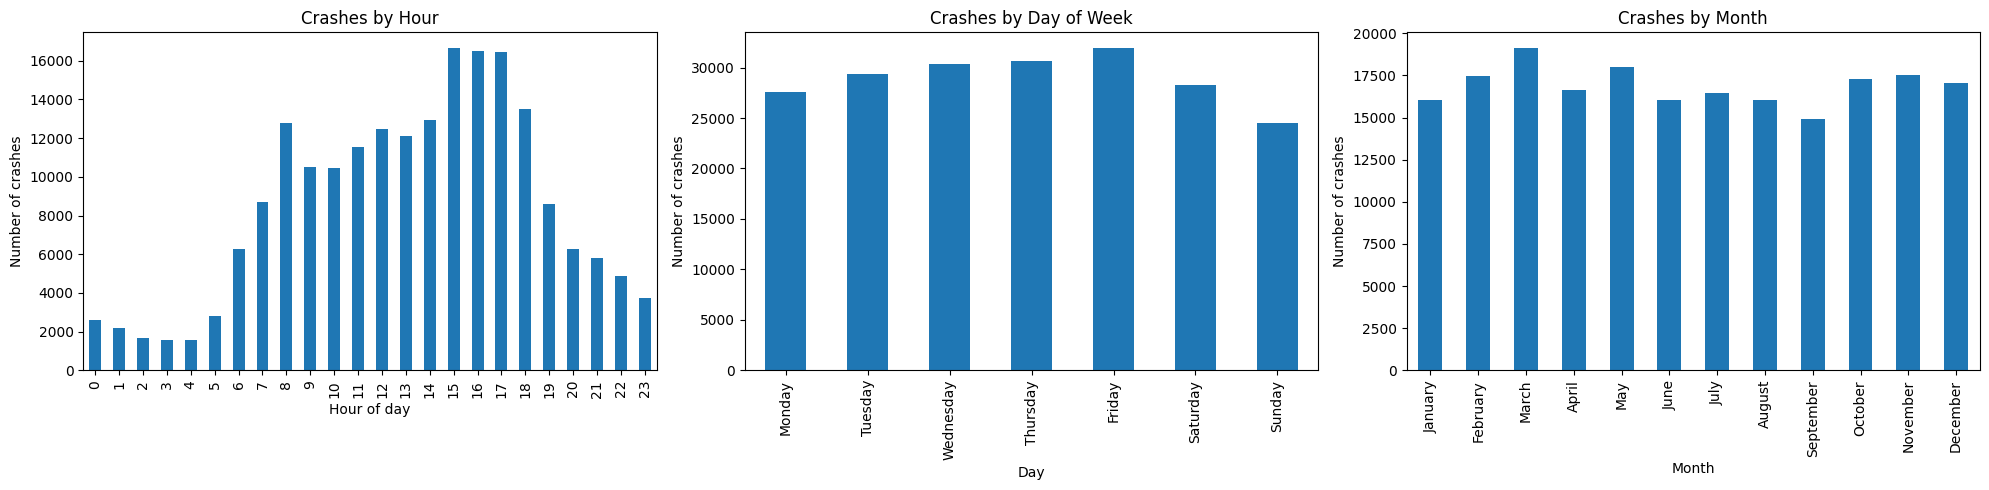

In [24]:

weekday_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

month_order = [
    "January", "February", "March",
    "April", "May", "June",
    "July", "August", "September",
    "October", "November", "December"
]

fig, axes = plt.subplots(1, 3, figsize=(20, 5))

# Hourly crashes
df["hour"].value_counts().sort_index().plot(
    kind="bar", ax=axes[0]
)
axes[0].set_title("Crashes by Hour")
axes[0].set_xlabel("Hour of day")
axes[0].set_ylabel("Number of crashes")

# Daily crashes
df["day_of_week"].value_counts().reindex(
    weekday_order
).plot(kind="bar", ax=axes[1])
axes[1].set_title("Crashes by Day of Week")
axes[1].set_xlabel("Day")
axes[1].set_ylabel("Number of crashes")

# Monthly crashes
df["month"].value_counts().reindex(
    month_order
).plot(kind="bar", ax=axes[2])
axes[2].set_title("Crashes by Month")
axes[2].set_xlabel("Month")
axes[2].set_ylabel("Number of crashes")

plt.tight_layout()
plt.show()


In [25]:
print("CRASHES BY HOUR")
display(df["hour"].value_counts().sort_index())

print("\nCRASHES BY DAY")
display(df["day_of_week"].value_counts().reindex(weekday_order))

print("\nCRASHES BY MONTH")
display(df["month"].value_counts().reindex(month_order))

CRASHES BY HOUR


,count
hour,
0,2617
1,2161
2,1676
3,1564
4,1554
5,2802
6,6267
7,8717
8,12795



CRASHES BY DAY


,count
day_of_week,
Monday,27562
Tuesday,29336
Wednesday,30342
Thursday,30625
Friday,31901
Saturday,28233
Sunday,24555



CRASHES BY MONTH


,count
month,
January,16038
February,17464
March,19106
April,16649
May,17986
June,16041
July,16439
August,16025
September,14923


## 8. Spatial analysis: where are crashes concentrated?

In [26]:
# Search all loaded datasets for possible coordinate columns

for name, dataset in data.items():
    coordinate_columns = [
        col for col in dataset.columns
        if any(word in col.lower() for word in [
            "latitude", "longitude", "longitude",
            "lat", "lon", "easting", "northing"
        ])
    ]

    print(f"\n{name.upper()}")
    print("Possible coordinate columns:", coordinate_columns)


ACCIDENT
Possible coordinate columns: []

ACCIDENT_EVENT
Possible coordinate columns: []

ACCIDENT_LOCATION
Possible coordinate columns: []

ATMOSPHERIC_COND
Possible coordinate columns: []

NODE
Possible coordinate columns: ['LATITUDE', 'LONGITUDE']

PERSON
Possible coordinate columns: []

ROAD_SURFACE_COND
Possible coordinate columns: []

VEHICLE
Possible coordinate columns: []

VICTORIAN_ROAD_CRASH_DATA
Possible coordinate columns: ['LATITUDE', 'LONGITUDE']


In [27]:
node_df = data["node"]

print("NODE dataset shape:", node_df.shape)
print("\nNODE columns:")
print(node_df.columns.tolist())

display(node_df.head())

NODE dataset shape: (407972, 11)

NODE columns:
['ACCIDENT_NO', 'NODE_ID', 'NODE_TYPE', 'AMG_X', 'AMG_Y', 'LGA_NAME', 'LGA NAME ALL', 'DEG_URBAN_NAME', 'LATITUDE', 'LONGITUDE', 'POSTCODE_CRASH']


,ACCIDENT_NO,NODE_ID,NODE_TYPE,AMG_X,AMG_Y,LGA_NAME,LGA NAME ALL,DEG_URBAN_NAME,LATITUDE,LONGITUDE,POSTCODE_CRASH
0,T20140013159,272777,N,2503749.988,2405640.141,STONNINGTON,"STONNINGTON,STONNINGTON",MELB_URBAN,-37.850290,145.04260,3144
1,T20140007111,272781,N,2532973.019,2411488.328,YARRA RANGES,"YARRA RANGES,YARRA RANGES",MELB_URBAN,-37.797020,145.37440,3796
2,T20140013443,272793,N,2476784.322,2417747.493,MELTON,"MELTON,MELTON",MELB_URBAN,-37.740917,144.73659,3023
3,T20140011483,272784,N,2483736.447,2412074.836,BRIMBANK,"BRIMBANK,BRIMBANK",MELB_URBAN,-37.792180,144.81534,3020
4,T20140013127,272788,N,2283055.434,2511262.011,HORSHAM,"HORSHAM,HORSHAM",RURAL_VICTORIA,-36.873510,142.56613,3385


In [28]:
node_df = data["node"]

print("NODE dataset shape:", node_df.shape)

print("\nActual NODE columns:")
for col in node_df.columns:
    print(col)

print("\nFirst five records:")
display(node_df.head())

print("\nData types:")
display(node_df.dtypes.to_frame("data_type"))

NODE dataset shape: (407972, 11)

Actual NODE columns:
ACCIDENT_NO
NODE_ID
NODE_TYPE
AMG_X
AMG_Y
LGA_NAME
LGA NAME ALL
DEG_URBAN_NAME
LATITUDE
LONGITUDE
POSTCODE_CRASH

First five records:


,ACCIDENT_NO,NODE_ID,NODE_TYPE,AMG_X,AMG_Y,LGA_NAME,LGA NAME ALL,DEG_URBAN_NAME,LATITUDE,LONGITUDE,POSTCODE_CRASH
0,T20140013159,272777,N,2503749.988,2405640.141,STONNINGTON,"STONNINGTON,STONNINGTON",MELB_URBAN,-37.850290,145.04260,3144
1,T20140007111,272781,N,2532973.019,2411488.328,YARRA RANGES,"YARRA RANGES,YARRA RANGES",MELB_URBAN,-37.797020,145.37440,3796
2,T20140013443,272793,N,2476784.322,2417747.493,MELTON,"MELTON,MELTON",MELB_URBAN,-37.740917,144.73659,3023
3,T20140011483,272784,N,2483736.447,2412074.836,BRIMBANK,"BRIMBANK,BRIMBANK",MELB_URBAN,-37.792180,144.81534,3020
4,T20140013127,272788,N,2283055.434,2511262.011,HORSHAM,"HORSHAM,HORSHAM",RURAL_VICTORIA,-36.873510,142.56613,3385



Data types:


,data_type
ACCIDENT_NO,object
NODE_ID,int64
NODE_TYPE,object
AMG_X,float64
AMG_Y,float64
LGA_NAME,object
LGA NAME ALL,object
DEG_URBAN_NAME,object
LATITUDE,float64
LONGITUDE,float64


In [29]:
keywords = [
    "lat", "lon", "long", "coord",
    "easting", "northing", "x", "y",
    "location", "node"
]

for col in node_df.columns:
    if any(word in col.lower() for word in keywords):
        print("Possible location field:", col)

Possible location field: NODE_ID
Possible location field: NODE_TYPE
Possible location field: AMG_X
Possible location field: AMG_Y
Possible location field: LATITUDE
Possible location field: LONGITUDE


In [30]:
print("Crash NODE_ID examples:")
display(crashes["NODE_ID"].head())

print("\nNODE table ID examples:")
display(node_df["NODE_ID"].head())

print("\nUnique crash NODE_IDs:", crashes["NODE_ID"].nunique())
print("Unique NODE table IDs:", node_df["NODE_ID"].nunique())

Crash NODE_ID examples:


,NODE_ID
0,277152.0
1,40762.0
2,609188.0
3,249923.0
4,249991.0



NODE table ID examples:


,NODE_ID
0,272777
1,272781
2,272793
3,272784
4,272788



Unique crash NODE_IDs: 144487
Unique NODE table IDs: 144484


Standardize the Node_Id

In [31]:
# Create copies to preserve original datasets
crashes = crashes.copy()
node_df = data["node"].copy()

# Convert NODE_ID to nullable integer
crashes["NODE_ID"] = pd.to_numeric(
    crashes["NODE_ID"], errors="coerce"
).round().astype("Int64")

node_df["NODE_ID"] = pd.to_numeric(
    node_df["NODE_ID"], errors="coerce"
).round().astype("Int64")

print("Crash NODE_ID dtype:", crashes["NODE_ID"].dtype)
print("NODE table NODE_ID dtype:", node_df["NODE_ID"].dtype)

Crash NODE_ID dtype: Int64
NODE table NODE_ID dtype: Int64


In [32]:
crash_node_ids = set(crashes["NODE_ID"].dropna())
reference_node_ids = set(node_df["NODE_ID"].dropna())

matched_ids = crash_node_ids.intersection(reference_node_ids)
unmatched_ids = crash_node_ids.difference(reference_node_ids)

print("Matching NODE IDs:", len(matched_ids))
print("Unmatched crash NODE IDs:", len(unmatched_ids))
print("Match percentage:", round(
    len(matched_ids) / len(crash_node_ids) * 100, 2
), "%")

print("\nExamples of unmatched IDs:")
print(list(unmatched_ids)[:10])

Matching NODE IDs: 144484
Unmatched crash NODE IDs: 3
Match percentage: 100.0 %

Examples of unmatched IDs:
[np.int64(-3), np.int64(-10), np.int64(-1)]


In [33]:
print("NODE TABLE COLUMNS:")
print(node_df.columns.tolist())

print("\nNODE TABLE PREVIEW:")
display(node_df.head(10))

NODE TABLE COLUMNS:
['ACCIDENT_NO', 'NODE_ID', 'NODE_TYPE', 'AMG_X', 'AMG_Y', 'LGA_NAME', 'LGA NAME ALL', 'DEG_URBAN_NAME', 'LATITUDE', 'LONGITUDE', 'POSTCODE_CRASH']

NODE TABLE PREVIEW:


,ACCIDENT_NO,NODE_ID,NODE_TYPE,AMG_X,AMG_Y,LGA_NAME,LGA NAME ALL,DEG_URBAN_NAME,LATITUDE,LONGITUDE,POSTCODE_CRASH
0,T20140013159,272777,N,2503749.988,2405640.141,STONNINGTON,"STONNINGTON,STONNINGTON",MELB_URBAN,-37.850290,145.04260,3144
1,T20140007111,272781,N,2532973.019,2411488.328,YARRA RANGES,"YARRA RANGES,YARRA RANGES",MELB_URBAN,-37.797020,145.37440,3796
2,T20140013443,272793,N,2476784.322,2417747.493,MELTON,"MELTON,MELTON",MELB_URBAN,-37.740917,144.73659,3023
3,T20140011483,272784,N,2483736.447,2412074.836,BRIMBANK,"BRIMBANK,BRIMBANK",MELB_URBAN,-37.792180,144.81534,3020
4,T20140013127,272788,N,2283055.434,2511262.011,HORSHAM,"HORSHAM,HORSHAM",RURAL_VICTORIA,-36.873510,142.56613,3385
5,T20140013604,272791,N,2446395.482,2382487.589,GEELONG,"GEELONG,GEELONG",LARGE_PROVINCIAL_CITIES,-38.057343,144.38922,3214
6,T20140013874,272792,N,2463566.004,2422833.638,MELTON,"MELTON,MELTON",RURAL_VICTORIA,-37.694668,144.58687,3338
7,T20140013946,272796,N,2508971.536,2386026.911,KINGSTON,"KINGSTON,KINGSTON",MELB_URBAN,-38.026960,145.10217,3195
8,T20140011885,272800,N,2540821.152,2455557.172,MURRINDINDI,"MURRINDINDI,MURRINDINDI,MURRINDINDI,MURRINDINDI",RURAL_VICTORIA,-37.399620,145.46109,3717
9,T20140011911,272801,N,2596867.393,2458052.069,MANSFIELD,"MANSFIELD,MANSFIELD",RURAL_VICTORIA,-37.373013,146.09380,3723


Check for the duplicate values


In [34]:
print(
    "Duplicate NODE_ID records:",
    node_df["NODE_ID"].duplicated().sum()
)

display(
    node_df[
        node_df["NODE_ID"].duplicated(keep=False)
    ].sort_values("NODE_ID").head(10)
)

Duplicate NODE_ID records: 263488


,ACCIDENT_NO,NODE_ID,NODE_TYPE,AMG_X,AMG_Y,LGA_NAME,LGA NAME ALL,DEG_URBAN_NAME,LATITUDE,LONGITUDE,POSTCODE_CRASH
293164,T20200019549,4,I,2497406.319,2416186.731,MORELAND,"MERRI-BEK,MERRI-BEK",MELB_URBAN,-37.75527,144.97057,3058
300399,T20120015275,4,I,2497406.319,2416186.731,MORELAND,"MERRI-BEK,MERRI-BEK",MELB_URBAN,-37.75527,144.97057,3058
300148,T20170014851,4,I,2497406.319,2416186.731,MORELAND,"MERRI-BEK,MERRI-BEK",MELB_URBAN,-37.75527,144.97057,3058
299027,T20210002031,4,I,2497406.319,2416186.731,MORELAND,"MERRI-BEK,MERRI-BEK",MELB_URBAN,-37.75527,144.97057,3058
299927,T20170014851,4,I,2497406.319,2416186.731,MORELAND,"MERRI-BEK,MERRI-BEK",MELB_URBAN,-37.75527,144.97057,3058
297918,T20240003412,4,I,2497406.319,2416186.731,MORELAND,"MERRI-BEK,MERRI-BEK",MELB_URBAN,-37.75527,144.97057,3058
295747,T20200019549,4,I,2497406.319,2416186.731,MORELAND,"MERRI-BEK,MERRI-BEK",MELB_URBAN,-37.75527,144.97057,3058
300607,T20120015275,4,I,2497406.319,2416186.731,MORELAND,"MERRI-BEK,MERRI-BEK",MELB_URBAN,-37.75527,144.97057,3058
298734,T20210002031,4,I,2497406.319,2416186.731,MORELAND,"MERRI-BEK,MERRI-BEK",MELB_URBAN,-37.75527,144.97057,3058
298293,T20240003412,4,I,2497406.319,2416186.731,MORELAND,"MERRI-BEK,MERRI-BEK",MELB_URBAN,-37.75527,144.97057,3058


In [35]:
node_df = data["node"].copy()

print("Columns:")
print(node_df.columns.tolist())

print("\nData types:")
print(node_df.dtypes)

print("\nFirst 10 rows:")
display(node_df.head(10))

Columns:
['ACCIDENT_NO', 'NODE_ID', 'NODE_TYPE', 'AMG_X', 'AMG_Y', 'LGA_NAME', 'LGA NAME ALL', 'DEG_URBAN_NAME', 'LATITUDE', 'LONGITUDE', 'POSTCODE_CRASH']

Data types:
ACCIDENT_NO        object
NODE_ID             int64
NODE_TYPE          object
AMG_X             float64
AMG_Y             float64
LGA_NAME           object
LGA NAME ALL       object
DEG_URBAN_NAME     object
LATITUDE          float64
LONGITUDE         float64
POSTCODE_CRASH      int64
dtype: object

First 10 rows:


,ACCIDENT_NO,NODE_ID,NODE_TYPE,AMG_X,AMG_Y,LGA_NAME,LGA NAME ALL,DEG_URBAN_NAME,LATITUDE,LONGITUDE,POSTCODE_CRASH
0,T20140013159,272777,N,2503749.988,2405640.141,STONNINGTON,"STONNINGTON,STONNINGTON",MELB_URBAN,-37.850290,145.04260,3144
1,T20140007111,272781,N,2532973.019,2411488.328,YARRA RANGES,"YARRA RANGES,YARRA RANGES",MELB_URBAN,-37.797020,145.37440,3796
2,T20140013443,272793,N,2476784.322,2417747.493,MELTON,"MELTON,MELTON",MELB_URBAN,-37.740917,144.73659,3023
3,T20140011483,272784,N,2483736.447,2412074.836,BRIMBANK,"BRIMBANK,BRIMBANK",MELB_URBAN,-37.792180,144.81534,3020
4,T20140013127,272788,N,2283055.434,2511262.011,HORSHAM,"HORSHAM,HORSHAM",RURAL_VICTORIA,-36.873510,142.56613,3385
5,T20140013604,272791,N,2446395.482,2382487.589,GEELONG,"GEELONG,GEELONG",LARGE_PROVINCIAL_CITIES,-38.057343,144.38922,3214
6,T20140013874,272792,N,2463566.004,2422833.638,MELTON,"MELTON,MELTON",RURAL_VICTORIA,-37.694668,144.58687,3338
7,T20140013946,272796,N,2508971.536,2386026.911,KINGSTON,"KINGSTON,KINGSTON",MELB_URBAN,-38.026960,145.10217,3195
8,T20140011885,272800,N,2540821.152,2455557.172,MURRINDINDI,"MURRINDINDI,MURRINDINDI,MURRINDINDI,MURRINDINDI",RURAL_VICTORIA,-37.399620,145.46109,3717
9,T20140011911,272801,N,2596867.393,2458052.069,MANSFIELD,"MANSFIELD,MANSFIELD",RURAL_VICTORIA,-37.373013,146.09380,3723


In [36]:
print("Total NODE rows:", len(node_df))
print("Unique NODE_IDs:", node_df["NODE_ID"].nunique())
print("Missing NODE_IDs:", node_df["NODE_ID"].isna().sum())
print("Duplicate NODE_ID rows:", node_df["NODE_ID"].duplicated().sum())

Total NODE rows: 407972
Unique NODE_IDs: 144484
Missing NODE_IDs: 0
Duplicate NODE_ID rows: 263488


In [37]:
print("Missing latitudes:", node_df["LATITUDE"].isna().sum())
print("Missing longitudes:", node_df["LONGITUDE"].isna().sum())

display(
    node_df[["NODE_ID", "LATITUDE", "LONGITUDE"]].head(10)
)

Missing latitudes: 0
Missing longitudes: 0


,NODE_ID,LATITUDE,LONGITUDE
0,272777,-37.850290,145.04260
1,272781,-37.797020,145.37440
2,272793,-37.740917,144.73659
3,272784,-37.792180,144.81534
4,272788,-36.873510,142.56613
5,272791,-38.057343,144.38922
6,272792,-37.694668,144.58687
7,272796,-38.026960,145.10217
8,272800,-37.399620,145.46109
9,272801,-37.373013,146.09380


Prepare the coordinate data

In [38]:
node_locations = node_df[
    [
        "ACCIDENT_NO",
        "NODE_ID",
        "LATITUDE",
        "LONGITUDE",
        "LGA_NAME",
        "POSTCODE_CRASH"
    ]
].copy()

# Check whether each accident has one coordinate record
print("Total rows:", len(node_locations))
print("Unique accidents:", node_locations["ACCIDENT_NO"].nunique())
print("Duplicate accident numbers:",
      node_locations["ACCIDENT_NO"].duplicated().sum())

# Check missing coordinates
print("Missing latitude:", node_locations["LATITUDE"].isna().sum())
print("Missing longitude:", node_locations["LONGITUDE"].isna().sum())

Total rows: 407972
Unique accidents: 201279
Duplicate accident numbers: 206693
Missing latitude: 0
Missing longitude: 0


Check duplicate accident numbers

In [39]:
duplicate_locations = node_locations[
    node_locations.duplicated("ACCIDENT_NO", keep=False)
].sort_values("ACCIDENT_NO")

display(duplicate_locations.head(20))

,ACCIDENT_NO,NODE_ID,LATITUDE,LONGITUDE,LGA_NAME,POSTCODE_CRASH
176076,T20120000009,249102,-38.234955,145.72672,BAW BAW,3981
176952,T20120000009,249102,-38.234955,145.72672,BAW BAW,3981
129525,T20120000012,41780,-37.903540,145.16140,MONASH,3170
130044,T20120000012,41780,-37.903540,145.16140,MONASH,3170
355354,T20120000013,69811,-37.935940,145.09885,KINGSTON,3169
355421,T20120000013,69811,-37.935940,145.09885,KINGSTON,3169
107613,T20120000018,22636,-34.215874,142.04388,MILDURA,3505
107072,T20120000018,22636,-34.215874,142.04388,MILDURA,3505
176904,T20120000021,248597,-38.369560,144.77792,MORNINGTON PENINSULA,3942
176028,T20120000021,248597,-38.369560,144.77792,MORNINGTON PENINSULA,3942


In [ ]:
# Count duplicate accident numbers
print(
    "Duplicate ACCIDENT_NO values:",
    node_locations["ACCIDENT_NO"].duplicated().sum()
)

# Inspect accidents with multiple location records
duplicate_locations = node_locations[
    node_locations.duplicated("ACCIDENT_NO", keep=False)
].sort_values("ACCIDENT_NO")

display(duplicate_locations.head(30))

Duplicate ACCIDENT_NO values: 206693


,ACCIDENT_NO,NODE_ID,LATITUDE,LONGITUDE,LGA_NAME,POSTCODE_CRASH
176076,T20120000009,249102,-38.234955,145.72672,BAW BAW,3981
176952,T20120000009,249102,-38.234955,145.72672,BAW BAW,3981
129525,T20120000012,41780,-37.903540,145.16140,MONASH,3170
130044,T20120000012,41780,-37.903540,145.16140,MONASH,3170
355354,T20120000013,69811,-37.935940,145.09885,KINGSTON,3169
355421,T20120000013,69811,-37.935940,145.09885,KINGSTON,3169
107613,T20120000018,22636,-34.215874,142.04388,MILDURA,3505
107072,T20120000018,22636,-34.215874,142.04388,MILDURA,3505
176904,T20120000021,248597,-38.369560,144.77792,MORNINGTON PENINSULA,3942
176028,T20120000021,248597,-38.369560,144.77792,MORNINGTON PENINSULA,3942


In [40]:
duplicate_check = (
    node_locations
    .groupby("ACCIDENT_NO")
    .agg(
        records=("ACCIDENT_NO", "size"),
        unique_nodes=("NODE_ID", "nunique"),
        unique_latitudes=("LATITUDE", "nunique"),
        unique_longitudes=("LONGITUDE", "nunique"),
        unique_lgas=("LGA_NAME", "nunique"),
        unique_postcodes=("POSTCODE_CRASH", "nunique")
    )
    .reset_index()
)

print("Accidents with repeated location rows:",
      (duplicate_check["records"] > 1).sum())

print("\nAccidents with conflicting coordinates:")
display(
    duplicate_check[
        (duplicate_check["unique_latitudes"] > 1) |
        (duplicate_check["unique_longitudes"] > 1)
    ].head(20)
)

Accidents with repeated location rows: 200369

Accidents with conflicting coordinates:


,ACCIDENT_NO,records,unique_nodes,unique_latitudes,unique_longitudes,unique_lgas,unique_postcodes


In [41]:
node_locations_clean = node_locations.drop_duplicates(
    subset="ACCIDENT_NO",
    keep="first"
).copy()

print("Original location records:", len(node_locations))
print("Clean location records:", len(node_locations_clean))
print("Unique accident numbers:", node_locations_clean["ACCIDENT_NO"].nunique())

Original location records: 407972
Clean location records: 201279
Unique accident numbers: 201279


In [42]:
print("Total crash records:", len(crashes))
print(
    "Duplicate crash accident numbers:",
    crashes["ACCIDENT_NO"].duplicated().sum()
)

Total crash records: 202554
Duplicate crash accident numbers: 0


Merge coordinates into crashes

In [43]:
crashes_geo = crashes.merge(
    node_locations_clean[
        [
            "ACCIDENT_NO",
            "LATITUDE",
            "LONGITUDE",
            "LGA_NAME",
            "POSTCODE_CRASH"
        ]
    ],
    on="ACCIDENT_NO",
    how="left",
    validate="one_to_one",
    indicator=True
)

print("Original crashes:", len(crashes))
print("Merged crashes:", len(crashes_geo))

print("\nMerge status:")
print(crashes_geo["_merge"].value_counts())

print("\nMissing coordinates:")
print("Latitude:", crashes_geo["LATITUDE"].isna().sum())
print("Longitude:", crashes_geo["LONGITUDE"].isna().sum())

display(crashes_geo.head())

Original crashes: 202554
Merged crashes: 202554

Merge status:
_merge
both          201279
left_only       1275
right_only         0
Name: count, dtype: int64

Missing coordinates:
Latitude: 1275
Longitude: 1275


,ACCIDENT_NO,ACCIDENT_DATE,ACCIDENT_TIME,ACCIDENT_TYPE,ACCIDENT_TYPE_DESC,DAY_OF_WEEK,DAY_WEEK_DESC,DCA_CODE,DCA_DESC,LIGHT_CONDITION,NODE_ID,NO_OF_VEHICLES,NO_PERSONS_KILLED,NO_PERSONS_INJ_2,NO_PERSONS_INJ_3,NO_PERSONS_NOT_INJ,NO_PERSONS,POLICE_ATTEND,ROAD_GEOMETRY,ROAD_GEOMETRY_DESC,SEVERITY,SPEED_ZONE,RMA,NODE_ID_LOCATION,ROAD_ROUTE_1,ROAD_NAME,ROAD_TYPE,ROAD_NAME_INT,ROAD_TYPE_INT,DISTANCE_LOCATION,DIRECTION_LOCATION,EVENT_TYPE_DESC,OBJECT_TYPE_DESC,LATITUDE,LONGITUDE,LGA_NAME,POSTCODE_CRASH,_merge
0,T20120002354,2012-01-31,10:35:00,1,Collision with vehicle,3,Tuesday,121,RIGHT THROUGH,1,277152,2,0,1,1,1,3,1,1,Cross intersection,2,60,Arterial Highway,277152.0,9999.0,KINGS,WAY,YORK,STREET,0.0,NE,Collision,Not Applicable,-37.829544,144.96378,PORT PHILLIP,3205.0,both
1,T20120002508,2012-02-02,07:55:00,1,Collision with vehicle,5,Thursday,121,RIGHT THROUGH,1,40762,2,0,2,1,0,3,1,1,Cross intersection,2,70,Arterial Highway,40762.0,2750.0,BURWOOD,HIGHWAY,BLACKBURN,ROAD,0.0,E,Collision,Not Applicable,-37.852745,145.15192,WHITEHORSE,3151.0,both
2,T20120003232,2012-02-10,14:20:00,1,Collision with vehicle,6,Friday,121,RIGHT THROUGH,1,609188,2,0,1,0,2,3,1,5,Not at intersection,2,60,Arterial Other,609188.0,5970.0,HEATHERTON,ROAD,GAVAN,DRIVE,10.0,E,Collision,Not Applicable,-37.961050,145.14114,DANDENONG,3172.0,both
3,T20120004288,2012-02-17,08:40:00,1,Collision with vehicle,6,Friday,143,ENTERING PARKING,1,249923,2,0,0,1,1,2,2,5,Not at intersection,3,40,Arterial Other,249923.0,5979.0,ROYAL,PARADE,ROYAL FWD,PARADE SERVICE ROAD,81.0,S,Collision | Fell from vehicle,Not Applicable,-37.778908,144.96013,MELBOURNE,3054.0,both
4,T20120004516,2012-02-24,15:30:00,2,Struck Pedestrian,6,Friday,101,PED EMERGES FROM IN FRONT OF PARKED OR STATION...,1,249991,1,0,0,1,1,2,1,5,Not at intersection,3,50,Local Road,249991.0,9999.0,SUTTON,STREET,PEARL,STREET,22.0,W,Collision,Not Applicable,-37.792400,144.94131,MELBOURNE,3051.0,both


Save geographic dataset

In [44]:
crashes_geo.to_csv(
    "victorian_crashes_with_coordinates.csv",
    index=False
)

print("Geographic crash dataset saved successfully.")

Geographic crash dataset saved successfully.


##**Plot** **crash locations**

Valid crash locations: 201279


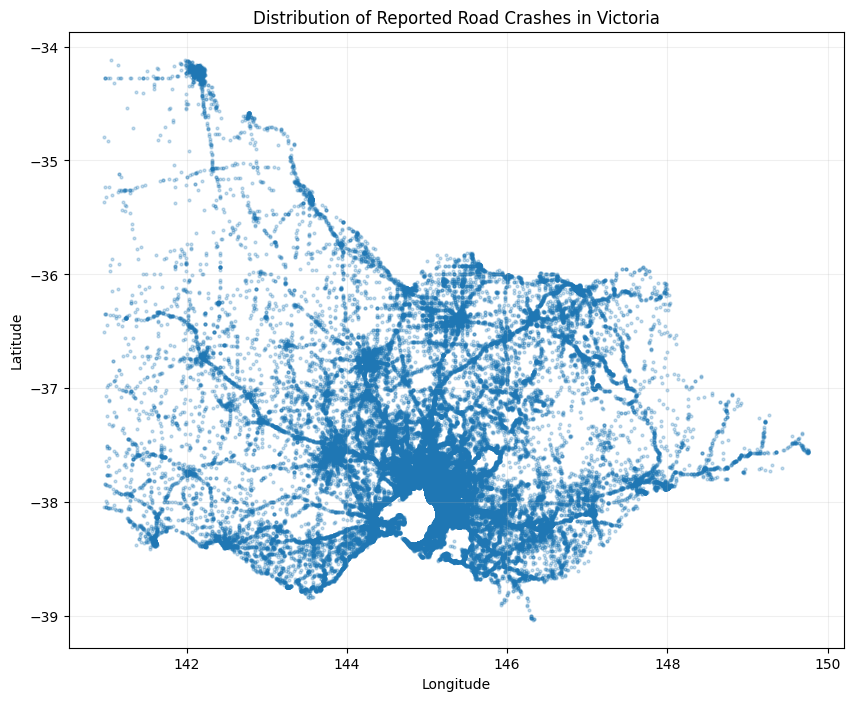

In [45]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Work with the geographic crash dataset
geo = crashes_geo.copy()

lat_col = "LATITUDE"
lon_col = "LONGITUDE"

# Convert coordinates to numeric
geo[lat_col] = pd.to_numeric(geo[lat_col], errors="coerce")
geo[lon_col] = pd.to_numeric(geo[lon_col], errors="coerce")

# Remove missing coordinates
geo = geo.dropna(subset=[lat_col, lon_col]).copy()

# Keep valid geographic coordinate ranges
geo = geo[
    geo[lat_col].between(-90, 90) &
    geo[lon_col].between(-180, 180)
].copy()

print("Valid crash locations:", len(geo))

# Plot
plt.figure(figsize=(10, 8))

plt.scatter(
    geo[lon_col],
    geo[lat_col],
    s=4,
    alpha=0.25
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Distribution of Reported Road Crashes in Victoria")
plt.grid(alpha=0.2)
plt.show()

Check coordinate distribution

In [46]:
print("Latitude range:")
print(geo["LATITUDE"].min(), geo["LATITUDE"].max())

print("\nLongitude range:")
print(geo["LONGITUDE"].min(), geo["LONGITUDE"].max())

print("\nCrashes by LGA:")
display(
    geo["LGA_NAME"]
    .value_counts()
    .head(15)
)

Latitude range:
-39.03083 -34.115696

Longitude range:
140.96648 149.75746

Crashes by LGA:


,count
LGA_NAME,
MELBOURNE,10456
CASEY,9180
GEELONG,7922
HUME,7337
DANDENONG,6926
BRIMBANK,6208
MONASH,6018
WHITTLESEA,6006
YARRA RANGES,5445


##**Prepare DBSCAN hotspot analysis**

In [47]:
from sklearn.cluster import DBSCAN
import numpy as np

# Extract coordinates in [latitude, longitude] order
coordinates = geo[["LATITUDE", "LONGITUDE"]].to_numpy()

# Convert degrees to radians
coordinates_rad = np.radians(coordinates)

# DBSCAN parameters
earth_radius_km = 6371.0088

# Example: points within 300 metres can be considered neighbours
eps_km = 0.3
eps_radians = eps_km / earth_radius_km

dbscan = DBSCAN(
    eps=eps_radians,
    min_samples=10,
    metric="haversine",
    algorithm="ball_tree"
)

geo["cluster"] = dbscan.fit_predict(coordinates_rad)

print("Total clusters:", geo.loc[geo["cluster"] != -1, "cluster"].nunique())
print("Noise points:", (geo["cluster"] == -1).sum())

print("\nLargest clusters:")
display(
    geo[geo["cluster"] != -1]["cluster"]
    .value_counts()
    .head(10)
)

Total clusters: 1016
Noise points: 49330

Largest clusters:


,count
cluster,
0,105932
3,4880
14,2150
19,1984
24,1495
63,837
49,811
62,547
25,508


The parameters 0.3 km and 10 are starting values for exploration, not established optimal thresholds. We should test alternative values and justify the final selection.

**Visualize the DBSCAN clusters**

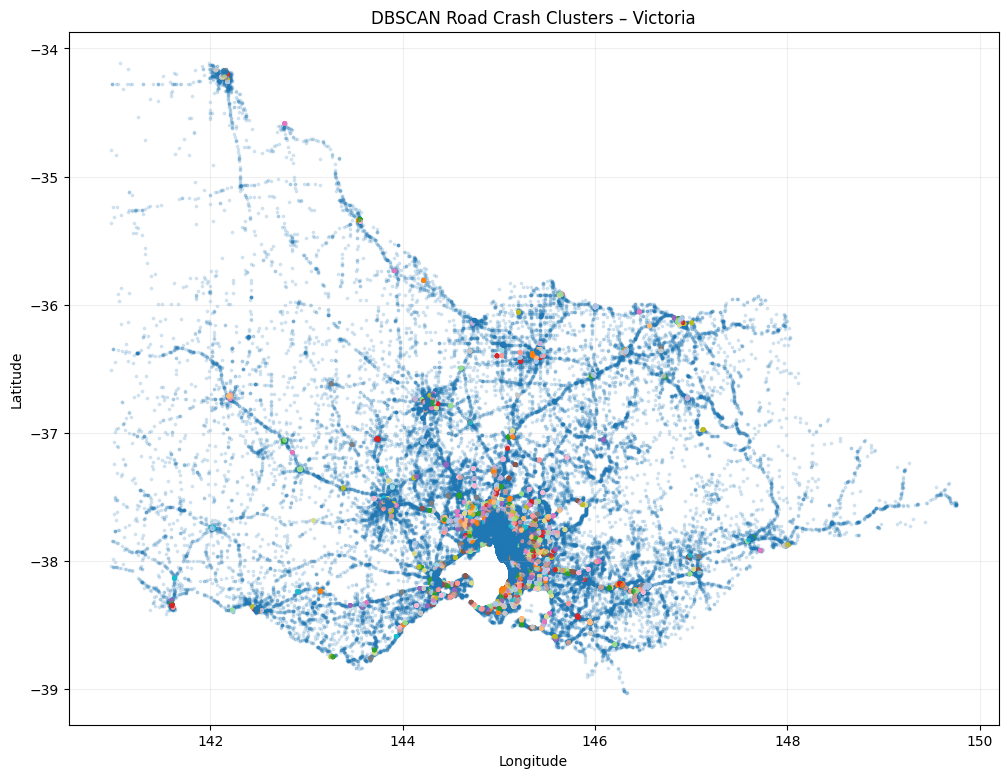

In [48]:
plt.figure(figsize=(12, 9))

clusters = geo["cluster"]

plt.scatter(
    geo.loc[clusters == -1, "LONGITUDE"],
    geo.loc[clusters == -1, "LATITUDE"],
    s=3,
    alpha=0.15,
    label="Noise"
)

clustered = geo[clusters != -1]

plt.scatter(
    clustered["LONGITUDE"],
    clustered["LATITUDE"],
    c=clustered["cluster"],
    cmap="tab20",
    s=5,
    alpha=0.6
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("DBSCAN Road Crash Clusters – Victoria")
plt.grid(alpha=0.2)
plt.show()

Summary of hotspot locations

In [49]:
hotspot_summary = (
    geo[geo["cluster"] != -1]
    .groupby("cluster")
    .agg(
        crash_count=("ACCIDENT_NO", "nunique"),
        mean_latitude=("LATITUDE", "mean"),
        mean_longitude=("LONGITUDE", "mean"),
        main_lga=("LGA_NAME", lambda x: x.mode().iloc[0])
    )
    .sort_values("crash_count", ascending=False)
)

display(hotspot_summary.head(15))

,crash_count,mean_latitude,mean_longitude,main_lga
cluster,,,,
0,105932,-37.831587,145.029796,MELBOURNE
3,4880,-38.143670,144.352759,GEELONG
14,2150,-38.128719,145.145830,FRANKSTON
19,1984,-37.569278,143.848588,BALLARAT
24,1495,-36.766018,144.272648,BENDIGO
63,837,-37.691623,144.571599,MELTON
49,811,-36.380183,145.406293,SHEPPARTON
62,547,-38.074884,145.475737,CARDINIA
25,508,-37.542488,143.822456,BALLARAT


Valid crash locations: 201279


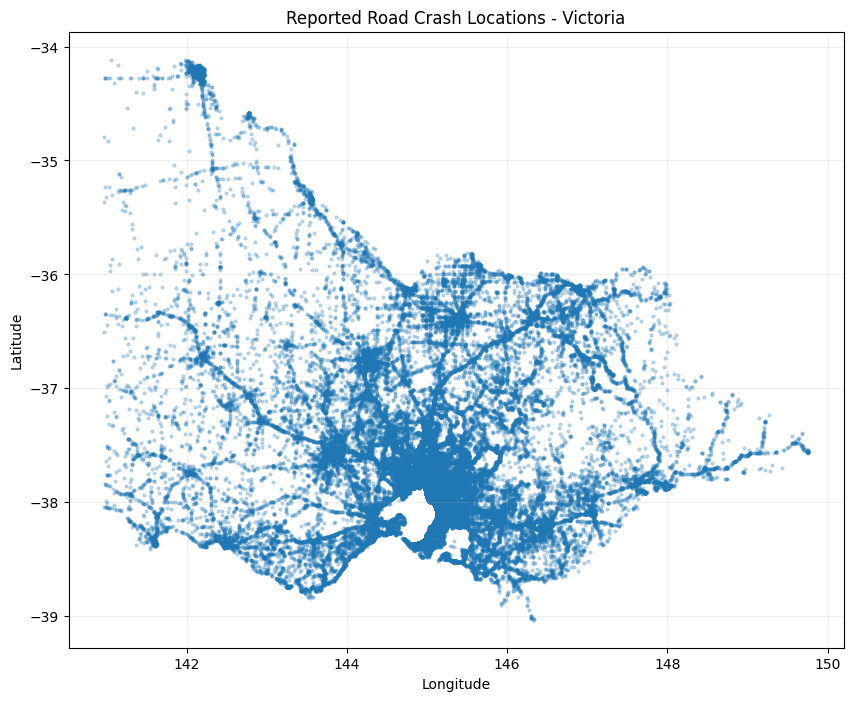

In [50]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Use the merged crash dataset
geo = crashes_geo.copy()

# Actual coordinate columns
lat_col = "LATITUDE"
lon_col = "LONGITUDE"

# Ensure coordinates are numeric
geo[lat_col] = pd.to_numeric(geo[lat_col], errors="coerce")
geo[lon_col] = pd.to_numeric(geo[lon_col], errors="coerce")

# Remove missing and invalid coordinates
geo = geo.dropna(subset=[lat_col, lon_col]).copy()

geo = geo[
    geo[lat_col].between(-90, 90) &
    geo[lon_col].between(-180, 180)
].copy()

print("Valid crash locations:", len(geo))

# Plot crash locations
plt.figure(figsize=(10, 8))
plt.scatter(
    geo[lon_col],
    geo[lat_col],
    s=4,
    alpha=0.25
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Reported Road Crash Locations - Victoria")
plt.grid(alpha=0.2)
plt.show()


Convert coordinates into a GeoDataFrame

In [51]:

!pip install geopandas -q

import geopandas as gpd

crash_gdf = gpd.GeoDataFrame(
    geo,
    geometry=gpd.points_from_xy(
        geo["LONGITUDE"],
        geo["LATITUDE"]
    ),
    crs="EPSG:4326"
)

print(crash_gdf.head())
print("Coordinate reference system:", crash_gdf.crs)


    ACCIDENT_NO ACCIDENT_DATE ACCIDENT_TIME  ACCIDENT_TYPE  \
0  T20120002354    2012-01-31      10:35:00              1   
1  T20120002508    2012-02-02      07:55:00              1   
2  T20120003232    2012-02-10      14:20:00              1   
3  T20120004288    2012-02-17      08:40:00              1   
4  T20120004516    2012-02-24      15:30:00              2   

       ACCIDENT_TYPE_DESC  DAY_OF_WEEK DAY_WEEK_DESC  DCA_CODE  \
0  Collision with vehicle            3       Tuesday       121   
1  Collision with vehicle            5      Thursday       121   
2  Collision with vehicle            6        Friday       121   
3  Collision with vehicle            6        Friday       143   
4       Struck Pedestrian            6        Friday       101   

                                            DCA_DESC  LIGHT_CONDITION  \
0                                      RIGHT THROUGH                1   
1                                      RIGHT THROUGH                1   
2          

DBSCAN hotspot analysis

In [52]:

from sklearn.cluster import DBSCAN
import numpy as np

# Haversine requires coordinates in radians
coordinates = np.radians(
    crash_gdf[["LATITUDE", "LONGITUDE"]].to_numpy()
)

earth_radius_km = 6371.0088
eps_km = 0.3

dbscan = DBSCAN(
    eps=eps_km / earth_radius_km,
    min_samples=10,
    metric="haversine",
    algorithm="ball_tree"
)

crash_gdf["cluster"] = dbscan.fit_predict(coordinates)

number_of_clusters = crash_gdf.loc[
    crash_gdf["cluster"] != -1, "cluster"
].nunique()

noise_points = (crash_gdf["cluster"] == -1).sum()

print("Number of hotspots:", number_of_clusters)
print("Noise observations:", noise_points)

display(
    crash_gdf["cluster"].value_counts().head(10)
)


Number of hotspots: 1016
Noise observations: 49330


,count
cluster,
0,105932
-1,49330
3,4880
14,2150
19,1984
24,1495
63,837
49,811
62,547


## 9. Crash severity analysis

Inspect the severity field

In [53]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("darkgrid")

df = crashes_geo.copy()

severity_col = "SEVERITY"

# Inspect severity categories
print("Severity data type:", df[severity_col].dtype)

print("\nSeverity distribution:")
display(
    df[severity_col]
    .value_counts(dropna=False)
    .to_frame("Number of crashes")
)

print("\nSeverity percentages:")
display(
    (df[severity_col].value_counts(normalize=True, dropna=False) * 100)
    .round(2)
    .to_frame("Percentage")
)


Severity data type: int64

Severity distribution:


,Number of crashes
SEVERITY,
3,126714
2,72430
1,3406
4,4



Severity percentages:


,Percentage
SEVERITY,
3,62.56
2,35.76
1,1.68
4,0.00


Visualize crash severity

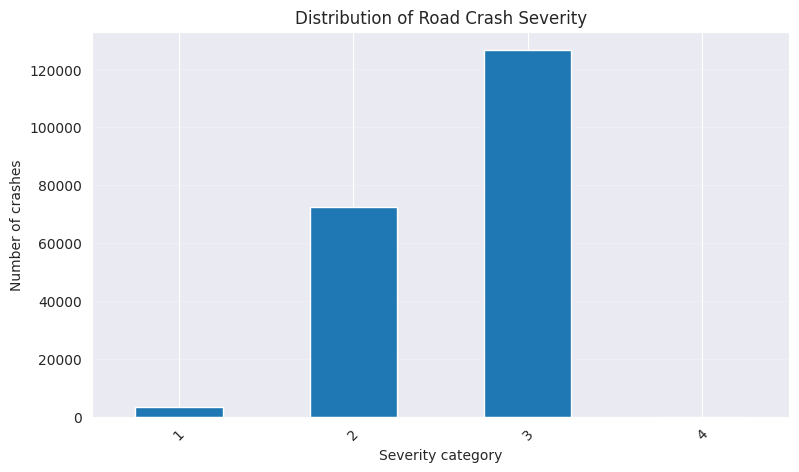

In [54]:

severity_counts = df[severity_col].value_counts().sort_index()

plt.figure(figsize=(9, 5))
severity_counts.plot(kind="bar")

plt.title("Distribution of Road Crash Severity")
plt.xlabel("Severity category")
plt.ylabel("Number of crashes")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.2)
plt.show()


Analyze severity by time

In [55]:

df["ACCIDENT_DATE"] = pd.to_datetime(
    df["ACCIDENT_DATE"],
    errors="coerce",
    dayfirst=True
)

df["month"] = df["ACCIDENT_DATE"].dt.month_name()
df["day_of_week"] = df["ACCIDENT_DATE"].dt.day_name()

# Extract hour from accident time
time_parsed = pd.to_datetime(
    df["ACCIDENT_TIME"].astype(str).str.strip(),
    format="%H:%M:%S",
    errors="coerce"
)

# Try HH:MM for values that did not parse
missing_time = time_parsed.isna()

time_parsed.loc[missing_time] = pd.to_datetime(
    df.loc[missing_time, "ACCIDENT_TIME"].astype(str).str.strip(),
    format="%H:%M",
    errors="coerce"
)

df["hour"] = time_parsed.dt.hour


Compare severity by hour

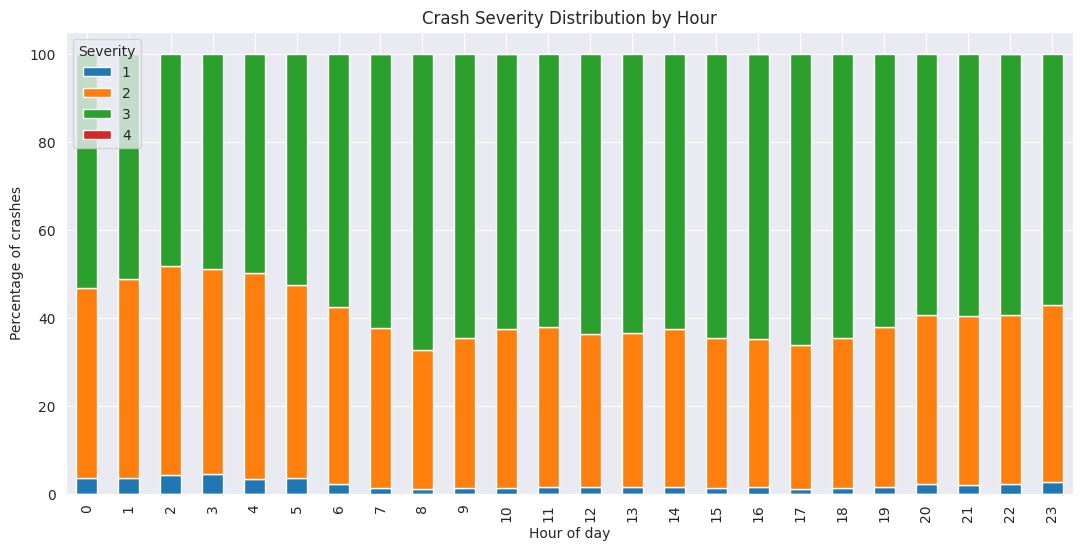

In [ ]:

severity_by_hour = pd.crosstab(
    df["hour"],
    df[severity_col],
    normalize="index"
) * 100

severity_by_hour.plot(
    kind="bar",
    stacked=True,
    figsize=(13, 6)
)

plt.title("Crash Severity Distribution by Hour")
plt.xlabel("Hour of day")
plt.ylabel("Percentage of crashes")
plt.legend(title="Severity")
plt.show()


Compare severity by day

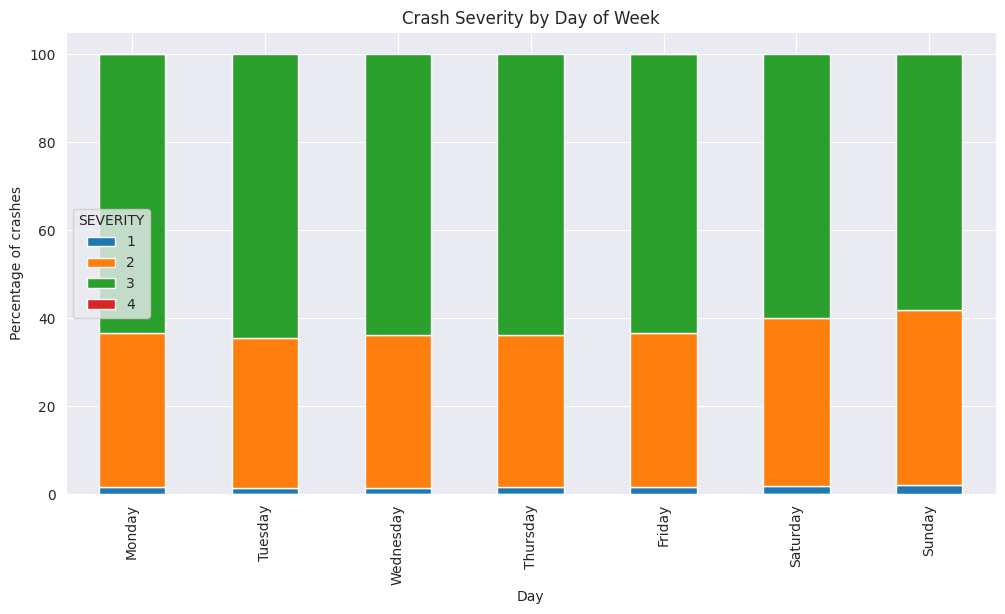

In [56]:

severity_by_day = pd.crosstab(
    df["day_of_week"],
    df[severity_col],
    normalize="index"
) * 100

day_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

severity_by_day = severity_by_day.reindex(day_order)

severity_by_day.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6)
)

plt.title("Crash Severity by Day of Week")
plt.xlabel("Day")
plt.ylabel("Percentage of crashes")
plt.show()


Analyze severity against road-user type

In [57]:

person_df = data["person"].copy()

print("PERSON table columns:")
print(person_df.columns.tolist())

display(person_df.head())


PERSON table columns:
['ACCIDENT_NO', 'PERSON_ID', 'VEHICLE_ID', 'SEX', 'AGE_GROUP', 'INJ_LEVEL', 'INJ_LEVEL_DESC', 'SEATING_POSITION', 'HELMET_BELT_WORN', 'ROAD_USER_TYPE', 'ROAD_USER_TYPE_DESC', 'LICENCE_STATE', 'TAKEN_HOSPITAL', 'EJECTED_CODE']


,ACCIDENT_NO,PERSON_ID,VEHICLE_ID,SEX,AGE_GROUP,INJ_LEVEL,INJ_LEVEL_DESC,SEATING_POSITION,HELMET_BELT_WORN,ROAD_USER_TYPE,ROAD_USER_TYPE_DESC,LICENCE_STATE,TAKEN_HOSPITAL,EJECTED_CODE
0,T20120002501,C,C,M,50-59,4,Not injured,D,1.0,2,Drivers,V,NaN,0.0
1,T20120002923,C,C,U,Unknown,4,Not injured,D,9.0,2,Drivers,Z,NaN,0.0
2,T20120004530,A,A,M,40-49,3,Other injury,D,1.0,2,Drivers,V,N,0.0
3,T20120005055,A,A,F,22-25,3,Other injury,D,9.0,2,Drivers,V,NaN,0.0
4,T20120006418,01,A,M,5-12,3,Other injury,LF,1.0,3,Passengers,NaN,N,0.0


Analyze weather and road conditions

In [58]:

atmospheric_df = data["atmospheric_cond"].copy()
surface_df = data["road_surface_cond"].copy()

print("Atmospheric condition columns:")
print(atmospheric_df.columns.tolist())

display(atmospheric_df.head())

print("\nRoad surface condition columns:")
print(surface_df.columns.tolist())

display(surface_df.head())


Atmospheric condition columns:
['ACCIDENT_NO', 'ATMOSPH_COND', 'ATMOSPH_COND_SEQ', 'ATMOSPH_COND_DESC']


,ACCIDENT_NO,ATMOSPH_COND,ATMOSPH_COND_SEQ,ATMOSPH_COND_DESC
0,T20140021847,1,1,Clear
1,T20150008877,1,0,Clear
2,T20170021439,1,1,Clear
3,T20200006858,2,0,Raining
4,T20220023805,1,1,Clear



Road surface condition columns:
['ACCIDENT_NO', 'SURFACE_COND', 'SURFACE_COND_DESC', 'SURFACE_COND_SEQ']


,ACCIDENT_NO,SURFACE_COND,SURFACE_COND_DESC,SURFACE_COND_SEQ
0,T20120001299,1,Dry,1
1,T20120001400,1,Dry,0
2,T20120001488,1,Dry,1
3,T20120001777,1,Dry,1
4,T20120001865,1,Dry,1


In [59]:
print([
    col for col in df.columns
    if any(word in col.upper() for word in
           ["ROAD", "LIGHT", "WEATHER", "SURFACE", "SPEED"])
])

['LIGHT_CONDITION', 'ROAD_GEOMETRY', 'ROAD_GEOMETRY_DESC', 'SPEED_ZONE', 'ROAD_ROUTE_1', 'ROAD_NAME', 'ROAD_TYPE', 'ROAD_NAME_INT', 'ROAD_TYPE_INT']


Check missing values and class imbalance

In [60]:

print("Missing severity values:", df[severity_col].isna().sum())

print("\nMissingness by column:")
missing_summary = (
    df.isna().mean() * 100
).sort_values(ascending=False)

display(missing_summary.head(20).to_frame("Missing percentage"))

print("\nSeverity class balance:")
class_balance = df[severity_col].value_counts(normalize=True) * 100

display(class_balance.round(2).to_frame("Percentage"))


Missing severity values: 0

Missingness by column:


,Missing percentage
RMA,4.382041
ROAD_TYPE,1.951085
ROAD_TYPE_INT,1.841484
ROAD_NAME_INT,1.028368
ROAD_NAME,0.717833
OBJECT_TYPE_DESC,0.632918
EVENT_TYPE_DESC,0.632918
DIRECTION_LOCATION,0.631930
LGA_NAME,0.631930
POSTCODE_CRASH,0.629462



Severity class balance:


,Percentage
SEVERITY,
3,62.56
2,35.76
1,1.68
4,0.00


## 10. Predictive modelling planning and safeguards

Choose the prediction task before training:

- **Severity classification:** among recorded crashes, predict a severity category. Use only features available at the intended prediction time; exclude leakage such as final casualty counts if they define the target.
- **Crash-risk prediction:** predict crashes for road-segment/time-window units. This requires both crash and non-crash periods, plus a defensible exposure definition.

Use a time-aware or spatially grouped train/test split where appropriate. A random row split can overstate performance when nearby crashes or repeated locations appear in both train and test sets.


##**Enrich crashes with Coordinates & Environmental Conditions**

In [61]:
# Deduplicate auxiliary tables to maintain 1 row per ACCIDENT_NO
node_one_row = (
    data["node"]
    .dropna(subset=["LATITUDE", "LONGITUDE"])
    .drop_duplicates(subset="ACCIDENT_NO", keep="first")
    [["ACCIDENT_NO", "LATITUDE", "LONGITUDE", "LGA_NAME", "DEG_URBAN_NAME"]]
)

atmos_one_row = (
    data["atmospheric_cond"]
    .sort_values("ATMOSPH_COND_SEQ")
    .drop_duplicates(subset="ACCIDENT_NO", keep="first")
    [["ACCIDENT_NO", "ATMOSPH_COND_DESC"]]
)

surface_one_row = (
    data["road_surface_cond"]
    .sort_values("SURFACE_COND_SEQ")
    .drop_duplicates(subset="ACCIDENT_NO", keep="first")
    [["ACCIDENT_NO", "SURFACE_COND_DESC"]]
)

# Merge onto our working crash-level dataframe
model_df = (
    crashes
    .merge(node_one_row, on="ACCIDENT_NO", how="left", validate="one_to_one")
    .merge(atmos_one_row, on="ACCIDENT_NO", how="left", validate="one_to_one")
    .merge(surface_one_row, on="ACCIDENT_NO", how="left", validate="one_to_one")
)

assert len(model_df) == len(crashes), "Row count changed during merge!"
print("Enriched modelling table shape:", model_df.shape)

Enriched modelling table shape: (202554, 39)


##Feature Engineering & Target Definition

In [62]:
# Filter out the 4 non-injury anomalies (SEVERITY == 4)
model_df = model_df[model_df["SEVERITY"].isin([1, 2, 3])].copy()

# Target: 1 = Fatal (1) or Serious Injury (2), 0 = Other Injury (3) this is a binary setup
model_df["IS_SEVERE"] = model_df["SEVERITY"].isin([1, 2]).astype(int)

# Temporal features
model_df["HOUR"] = pd.to_datetime(
    model_df["ACCIDENT_TIME"].astype(str).str[:8], format="%H:%M:%S", errors="coerce"
).dt.hour
model_df["MONTH"] = model_df["ACCIDENT_DATE"].dt.month
model_df["IS_WEEKEND"] = model_df["DAY_WEEK_DESC"].isin(["Saturday", "Sunday"]).astype(int)

# Clean SPEED_ZONE (valid posted speeds are typically 30 to 110 km/h)
model_df["SPEED_ZONE_CLEAN"] = model_df["SPEED_ZONE"].where(
    model_df["SPEED_ZONE"].between(30, 110), np.nan
)

# Interaction / road context features
model_df["IS_INTERSECTION"] = (model_df["ROAD_GEOMETRY_DESC"] != "Not at intersection").astype(int)
model_df["IS_RAINING"] = (model_df["ATMOSPH_COND_DESC"] == "Raining").astype(int)

print("Target distribution (IS_SEVERE):")
print(model_df["IS_SEVERE"].value_counts(normalize=True).round(4))

Target distribution (IS_SEVERE):
IS_SEVERE
0    0.6256
1    0.3744
Name: proportion, dtype: float64


##Research Question 1 & 4 (Spatial Hotspot Clustering & Ambulance Base Optimization)

In [63]:
from sklearn.cluster import DBSCAN, KMeans

# Filter valid coordinates
geo_df = model_df.dropna(subset=["LATITUDE", "LONGITUDE"]).copy()

# Identify dense crash hotspots via DBSCAN (eps = 250 meters)
coords_rad = np.radians(geo_df[["LATITUDE", "LONGITUDE"]].values)
kms_per_radian = 6371.0088
eps_rad = 0.25 / kms_per_radian  # 250m radius

# Sample recent 50,000 crashes if memory is constrained in Colab
geo_sample = geo_df.tail(50000).copy()
sample_rad = np.radians(geo_sample[["LATITUDE", "LONGITUDE"]].values)

db = DBSCAN(eps=eps_rad, min_samples=30, metric="haversine", n_jobs=-1)
geo_sample["HOTSPOT_CLUSTER"] = db.fit_predict(sample_rad)

top_hotspots = (
    geo_sample[geo_sample["HOTSPOT_CLUSTER"] != -1]
    .groupby("HOTSPOT_CLUSTER")
    .agg(
        crash_count=("ACCIDENT_NO", "count"),
        severe_rate=("IS_SEVERE", "mean"),
        center_lat=("LATITUDE", "mean"),
        center_lon=("LONGITUDE", "mean"),
        top_road=("ROAD_NAME", lambda s: s.mode().iloc[0] if not s.mode().empty else "Unknown")
    )
    .sort_values("crash_count", ascending=False)
)

print("Top 10 High-Density Crash Hotspots:")
display(top_hotspots.head(10))

# Weight fatal or serious crashes 3x higher than minor injury crashes
weights = np.where(geo_df["IS_SEVERE"] == 1, 3.0, 1.0)
kmeans = KMeans(n_clusters=10, random_state=42, n_init=10)
kmeans.fit(geo_df[["LATITUDE", "LONGITUDE"]], sample_weight=weights)

ambulance_bases = pd.DataFrame(
    kmeans.cluster_centers_, columns=["BASE_LATITUDE", "BASE_LONGITUDE"]
)
ambulance_bases["ASSIGNED_CRASHES"] = pd.Series(kmeans.labels_).value_counts().sort_index().values
print("\nProposed Severity-Weighted Ambulance Base Coordinates:")
display(ambulance_bases)

Top 10 High-Density Crash Hotspots:


,crash_count,severe_rate,center_lat,center_lon,top_road
HOTSPOT_CLUSTER,,,,,
5,1454,0.292297,-37.814562,144.962342,ELIZABETH
16,160,0.362500,-37.849875,144.993591,CHAPEL
20,156,0.467949,-37.851541,144.980821,ST KILDA
10,118,0.262712,-37.799237,144.990277,HODDLE
2,104,0.221154,-37.690934,144.958232,SYDNEY
17,96,0.385417,-37.864997,144.983875,ST KILDA
11,95,0.378947,-37.987472,145.213021,FOSTER
1,91,0.241758,-37.685525,145.068050,PLENTY
32,88,0.250000,-37.796236,144.978680,BRUNSWICK



Proposed Severity-Weighted Ambulance Base Coordinates:


,BASE_LATITUDE,BASE_LONGITUDE,ASSIGNED_CRASHES
0,-37.755280,144.927649,88686
1,-34.724091,142.456964,2296
2,-37.766138,147.654123,2979
3,-37.693532,142.320726,4988
4,-36.494910,145.419524,6384
5,-37.976321,145.219363,59561
6,-38.009630,144.127058,16992
7,-38.165937,146.150060,7912
8,-36.767505,144.159657,7295
9,-36.417324,146.774366,4182


##Research Question 3: Crash Severity Classification (Preprocessing & Split)

In [64]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_features = [
    "HOUR", "MONTH", "IS_WEEKEND", "SPEED_ZONE_CLEAN",
    "NO_OF_VEHICLES", "NO_PERSONS", "IS_INTERSECTION", "IS_RAINING"
]

categorical_features = [
    "ACCIDENT_TYPE_DESC", "ROAD_GEOMETRY_DESC", "RMA",
    "ATMOSPH_COND_DESC", "SURFACE_COND_DESC", "DEG_URBAN_NAME"
]

X = model_df[numeric_features + categorical_features]
y = model_df["IS_SEVERE"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]), numeric_features),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
            ("ohe", OneHotEncoder(handle_unknown="ignore", min_frequency=50))
        ]), categorical_features)
    ]
)

print(f"Training set: {X_train.shape}, Test set: {X_test.shape}")

Training set: (162040, 14), Test set: (40510, 14)


##Train & Compare Baseline against Gradient Boosted Models

In [65]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import classification_report, roc_auc_score

# Baseline: Logistic Regression
log_reg_pipe = Pipeline([
    ("prep", preprocessor),
    ("clf", LogisticRegression(max_iter=500, class_weight="balanced", random_state=42))
])
log_reg_pipe.fit(X_train, y_train)
lr_preds = log_reg_pipe.predict(X_test)
lr_probs = log_reg_pipe.predict_proba(X_test)[:, 1]

print("LOGISTIC REGRESSION (BASELINE)")
print(f"ROC-AUC: {roc_auc_score(y_test, lr_probs):.4f}")
print(classification_report(y_test, lr_preds, target_names=["Other Injury", "Fatal/Serious"]))


# Convert sparse OHE output to dense for HistGradientBoosting
dense_preprocessor = ColumnTransformer(
    transformers=[
        ("num", SimpleImputer(strategy="median"), numeric_features),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
            ("ohe", OneHotEncoder(handle_unknown="ignore", min_frequency=50, sparse_output=False))
        ]), categorical_features)
    ]
)

hgb_pipe = Pipeline([
    ("prep", dense_preprocessor),
    ("clf", HistGradientBoostingClassifier(
        max_iter=200, learning_rate=0.08, max_depth=6,
        class_weight="balanced", random_state=42
    ))
])
hgb_pipe.fit(X_train, y_train)
hgb_preds = hgb_pipe.predict(X_test)
hgb_probs = hgb_pipe.predict_proba(X_test)[:, 1]

print("HIST GRADIENT BOOSTING")
print(f"ROC-AUC: {roc_auc_score(y_test, hgb_probs):.4f}")
print(classification_report(y_test, hgb_preds, target_names=["Other Injury", "Fatal/Serious"]))

LOGISTIC REGRESSION (BASELINE)
ROC-AUC: 0.6405
               precision    recall  f1-score   support

 Other Injury       0.71      0.64      0.67     25343
Fatal/Serious       0.48      0.57      0.52     15167

     accuracy                           0.61     40510
    macro avg       0.60      0.60      0.60     40510
 weighted avg       0.63      0.61      0.62     40510

HIST GRADIENT BOOSTING
ROC-AUC: 0.6539
               precision    recall  f1-score   support

 Other Injury       0.72      0.64      0.68     25343
Fatal/Serious       0.49      0.58      0.53     15167

     accuracy                           0.62     40510
    macro avg       0.60      0.61      0.60     40510
 weighted avg       0.63      0.62      0.62     40510



##Feature Importance (Key Drivers of Crash Severity)

,feature,importance_mean,importance_std
8,ACCIDENT_TYPE_DESC,0.030753,0.001602
3,SPEED_ZONE_CLEAN,0.025599,0.002351
12,SURFACE_COND_DESC,0.015780,0.002137
5,NO_PERSONS,0.011225,0.002952
0,HOUR,0.009371,0.001437
11,ATMOSPH_COND_DESC,0.008838,0.001449
13,DEG_URBAN_NAME,0.008650,0.001229
4,NO_OF_VEHICLES,0.005785,0.001240
9,ROAD_GEOMETRY_DESC,0.005554,0.001080
10,RMA,0.002961,0.000466


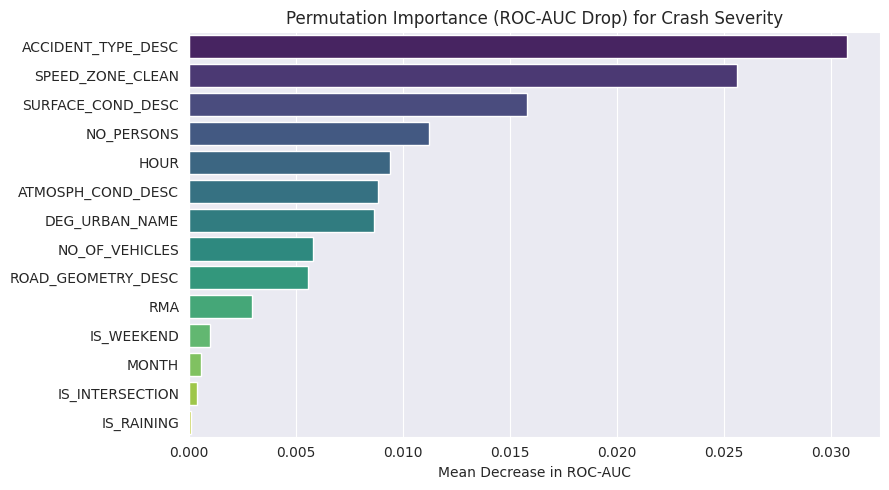

In [66]:
from sklearn.inspection import permutation_importance

# Permutation importance on a 10,000-row slice of X_test for speed
X_test_sub = X_test.iloc[:10000]
y_test_sub = y_test.iloc[:10000]

perm_result = permutation_importance(
    hgb_pipe, X_test_sub, y_test_sub,
    n_repeats=5, random_state=42, scoring="roc_auc", n_jobs=-1
)

importance_df = pd.DataFrame({
    "feature": X_test.columns,
    "importance_mean": perm_result.importances_mean,
    "importance_std": perm_result.importances_std
}).sort_values("importance_mean", ascending=False)

display(importance_df)

plt.figure(figsize=(9, 5))
sns.barplot(data=importance_df, x="importance_mean", y="feature", palette="viridis")
plt.title("Permutation Importance (ROC-AUC Drop) for Crash Severity")
plt.xlabel("Mean Decrease in ROC-AUC")
plt.ylabel("")
plt.tight_layout()
plt.show()

##Research Question 5: Risk-Weighted Fastest & Safest Routing Prototype

In [67]:
import networkx as nx
from sklearn.neighbors import NearestNeighbors

# Build a prototype spatial graph from top 500 high-frequency crash nodes
nodes_df = (
    geo_df.groupby(["NODE_ID"], as_index=False)
    .agg(
        LATITUDE=("LATITUDE", "mean"),
        LONGITUDE=("LONGITUDE", "mean"),
        crash_count=("ACCIDENT_NO", "count"),
        severe_count=("IS_SEVERE", "sum")
    )
    .sort_values("crash_count", ascending=False)
    .head(500)
    .reset_index(drop=True)
)

# Connect each node to its 5 nearest geographic neighbors
nbrs = NearestNeighbors(n_neighbors=6, metric="haversine").fit(
    np.radians(nodes_df[["LATITUDE", "LONGITUDE"]])
)
distances_rad, indices = nbrs.kneighbors(np.radians(nodes_df[["LATITUDE", "LONGITUDE"]]))

G = nx.Graph()
for idx, row in nodes_df.iterrows():
    G.add_node(idx, pos=(row["LONGITUDE"], row["LATITUDE"]), risk=row["severe_count"])

alpha = 0.5  # Safety penalty weight
max_risk = nodes_df["severe_count"].max() or 1

for i in range(len(nodes_df)):
    for j_idx, dist_rad in zip(indices[i][1:], distances_rad[i][1:]):
        dist_km = dist_rad * 6371.0088
        est_time_min = (dist_km / 50.0) * 60.0
        edge_risk = (nodes_df.loc[i, "severe_count"] + nodes_df.loc[j_idx, "severe_count"]) / (2 * max_risk)
        combined_cost = est_time_min * (1 + alpha * edge_risk)
        G.add_edge(i, j_idx, time=est_time_min, risk_cost=combined_cost)

# Route from Ambulance Base Node 0 to High Crash Node 50
fastest_path = nx.shortest_path(G, source=0, target=50, weight="time")
safest_fast_path = nx.shortest_path(G, source=0, target=50, weight="risk_cost")

print("Fastest path nodes:", fastest_path)
print("Safest-fastest path nodes:", safest_fast_path)

Fastest path nodes: [0, 169, np.int64(218), 50]
Safest-fastest path nodes: [0, 169, np.int64(218), 50]


## 11. Ambulance station location optimization

This stage needs more than crash points. Ideally obtain:
- candidate station locations or feasible sites,
- demand points (for example, validated crash hotspots or population-weighted demand),
- road-network travel times rather than straight-line distances,
- ambulance capacity/fleet assumptions and a target response-time threshold.

A p-median model can minimize weighted demand-to-station travel cost for a chosen number of stations. A capacitated facility-location model can additionally represent station/fleet capacity. Document assumptions and compare scenarios.


In [68]:
!pip install -q pulp osmnx networkx
import pulp
import networkx as nx
from sklearn.neighbors import NearestNeighbors

#  Define Demand Points
geo_valid = model_df.dropna(subset=["LATITUDE", "LONGITUDE"]).copy()
geo_valid["LAT_BIN"] = geo_valid["LATITUDE"].round(2)
geo_valid["LON_BIN"] = geo_valid["LONGITUDE"].round(2)

# Annualize demand (adjust n_years based on your dataset's date span)
n_years = max(1, geo_valid["ACCIDENT_DATE"].dt.year.nunique())

demand_df = (
    geo_valid.groupby(["LAT_BIN", "LON_BIN"], as_index=False)
    .agg(
        LATITUDE=("LATITUDE", "mean"),
        LONGITUDE=("LONGITUDE", "mean"),
        total_crashes=("ACCIDENT_NO", "count"),
        severe_crashes=("IS_SEVERE", "sum"),
        urban_area=("DEG_URBAN_NAME", lambda s: s.mode().iloc[0] if not s.mode().empty else "Unknown")
    )
)
# Severity-weighted annual emergency demand
demand_df["annual_weighted_demand"] = (
    (demand_df["severe_crashes"] * 3.0 + (demand_df["total_crashes"] - demand_df["severe_crashes"])) / n_years
)
demand_df = demand_df.sort_values("annual_weighted_demand", ascending=False).head(60).reset_index(drop=True)
demand_df["DEMAND_ID"] = [f"D_{i}" for i in range(len(demand_df))]

# In production, replace with actual hospital, fire station, or municipal depot coordinates
candidate_df = (
    geo_valid[geo_valid["RMA"].isin(["Freeway", "Arterial Highway", "Arterial Other"])]
    .groupby(["LAT_BIN", "LON_BIN"], as_index=False)
    .agg(LATITUDE=("LATITUDE", "mean"), LONGITUDE=("LONGITUDE", "mean"), count=("ACCIDENT_NO", "count"))
    .sort_values("count", ascending=False)
    .head(20)
    .reset_index(drop=True)
)
candidate_df["SITE_ID"] = [f"S_{j}" for j in range(len(candidate_df))]

# Uses OSMnx road graph if available, otherwise circuity-adjusted arterial network
def compute_travel_time_matrix(demands, sites, use_osmnx=False):
    M, N = len(demands), len(sites)
    travel_times = np.zeros((M, N))

    if use_osmnx:
        import osmnx as ox
        center_lat, center_lon = demands["LATITUDE"].mean(), demands["LONGITUDE"].mean()
        G = ox.graph_from_point((center_lat, center_lon), dist=25000, network_type="drive")
        G = ox.add_edge_speeds(G)
        G = ox.add_edge_travel_times(G)

        d_nodes = ox.nearest_nodes(G, demands["LONGITUDE"], demands["LATITUDE"])
        s_nodes = ox.nearest_nodes(G, sites["LONGITUDE"], sites["LATITUDE"])

        for j, s_node in enumerate(s_nodes):
            lengths = nx.single_source_dijkstra_path_length(G, s_node, weight="travel_time")
            for i, d_node in enumerate(d_nodes):
                travel_times[i, j] = lengths.get(d_node, 999.0) / 60.0
    else:
        # Circuity-adjusted network approximation
        CIRCUITY_FACTOR = 1.35
        AVG_SPEED_KMH = 42.0

        d_rad = np.radians(demands[["LATITUDE", "LONGITUDE"]].values)
        s_rad = np.radians(sites[["LATITUDE", "LONGITUDE"]].values)

        for i in range(M):
            dlat = s_rad[:, 0] - d_rad[i, 0]
            dlon = s_rad[:, 1] - d_rad[i, 1]
            a = np.sin(dlat / 2)**2 + np.cos(d_rad[i, 0]) * np.cos(s_rad[:, 0]) * np.sin(dlon / 2)**2
            dist_km = 2 * 6371.0088 * np.arcsin(np.sqrt(a))
            road_km = dist_km * CIRCUITY_FACTOR
            travel_times[i, :] = (road_km / AVG_SPEED_KMH) * 60.0

    return travel_times

# Set use_osmnx=True when running on a focused city bbox
t_matrix = compute_travel_time_matrix(demand_df, candidate_df, use_osmnx=False)
print(f"Travel time matrix shape: {t_matrix.shape} | Median travel time: {np.median(t_matrix):.1f} mins")

Travel time matrix shape: (60, 20) | Median travel time: 13.4 mins


In [73]:
from scipy.optimize import milp, LinearConstraint, Bounds

def solve_ambulance_optimization(
    demand_df,
    candidate_df,
    t_matrix,
    p_stations=6,
    capacitated=False,
    station_capacity=450.0,
    t_threshold=10.0,
    over_threshold_penalty=25.0
):
    M = len(demand_df)
    N = len(candidate_df)
    w = demand_df["annual_weighted_demand"].values


    num_vars = N + M * N

    # Effective travel cost including penalty if response time exceeds t_threshold
    cost_matrix = np.where(
        t_matrix <= t_threshold,
        t_matrix,
        t_matrix + over_threshold_penalty
    )

    # Objective vector c
    c = np.zeros(num_vars)
    for i in range(M):
        for j in range(N):
            c[N + i * N + j] = w[i] * cost_matrix[i, j]

    # Variable bounds [0, 1] and integrality
    lb = np.zeros(num_vars)
    ub = np.ones(num_vars)
    integrality = np.zeros(num_vars)
    integrality[:N] = 1
    if not capacitated:
        integrality[N:] = 1

    rows = []
    rhs_lb = []
    rhs_ub = []

    # Open exactly p stations (sum(y_j) == p_stations)
    row_p = np.zeros(num_vars)
    row_p[:N] = 1.0
    rows.append(row_p)
    rhs_lb.append(p_stations)
    rhs_ub.append(p_stations)

    # Every demand zone i must be 100% served (sum_j x_{i,j} == 1)
    for i in range(M):
        row_d = np.zeros(num_vars)
        row_d[N + i * N : N + (i + 1) * N] = 1.0
        rows.append(row_d)
        rhs_lb.append(1.0)
        rhs_ub.append(1.0)

    # Can only assign demand to an opened station (x_{i,j} - y_j <= 0)
    for i in range(M):
        for j in range(N):
            row_link = np.zeros(num_vars)
            row_link[j] = -1.0
            row_link[N + i * N + j] = 1.0
            rows.append(row_link)
            rhs_lb.append(-np.inf)
            rhs_ub.append(0.0)

    # (Capacitated Only): sum_i (w_i * x_{i,j}) - capacity * y_j <= 0
    if capacitated:
        for j in range(N):
            row_cap = np.zeros(num_vars)
            row_cap[j] = -station_capacity
            for i in range(M):
                row_cap[N + i * N + j] = w[i]
            rows.append(row_cap)
            rhs_lb.append(-np.inf)
            rhs_ub.append(0.0)

    A = np.array(rows)
    constraints = LinearConstraint(A, rhs_lb, rhs_ub)
    bounds = Bounds(lb, ub)

    res = milp(c=c, integrality=integrality, bounds=bounds, constraints=constraints)

    if not res.success:
        return {
            "Scenario": f"{'Capacitated' if capacitated else 'P-Median'} (p={p_stations})",
            "Status": f"Infeasible ({res.message})",
            "Stations_Opened": 0,
            "Selected_Sites": [],
            "Avg_Weighted_Response_Min": np.nan,
            f"Pct_Demand_Within_{int(t_threshold)}m": 0.0,
            "Max_Station_Load": 0.0,
            "Max_Capacity_Util_Pct": np.nan
        }

    sol = res.x
    y_sol = sol[:N]
    x_sol = sol[N:].reshape(M, N)

    opened_indices = [j for j in range(N) if y_sol[j] > 0.5]
    total_demand = w.sum()
    total_weighted_time = np.sum((w[:, None] * t_matrix) * x_sol)
    covered_demand = np.sum(w[:, None] * x_sol * (t_matrix <= t_threshold))

    station_loads = {
        candidate_df.loc[j, "SITE_ID"]: float(np.sum(w * x_sol[:, j]))
        for j in opened_indices
    }

    avg_response_min = total_weighted_time / total_demand
    pct_covered = (covered_demand / total_demand) * 100.0
    max_utilization = (max(station_loads.values()) / station_capacity) * 100.0 if capacitated else np.nan

    return {
        "Scenario": f"{'Capacitated' if capacitated else 'P-Median'} (p={p_stations})",
        "Status": "Optimal",
        "Stations_Opened": len(opened_indices),
        "Selected_Sites": [candidate_df.loc[j, "SITE_ID"] for j in opened_indices],
        "Avg_Weighted_Response_Min": round(avg_response_min, 2),
        f"Pct_Demand_Within_{int(t_threshold)}m": round(pct_covered, 1),
        "Max_Station_Load": round(max(station_loads.values()), 1),
        "Max_Capacity_Util_Pct": round(max_utilization, 1) if capacitated else "Unconstrained"
    }

In [74]:
# Estimate realistic per-station annual capacity
total_annual_demand = demand_df["annual_weighted_demand"].sum()
base_capacity = np.ceil(total_annual_demand / 4.5)

scenarios = [
    {"p_stations": 4, "capacitated": False, "station_capacity": base_capacity, "t_threshold": 10.0},
    {"p_stations": 6, "capacitated": False, "station_capacity": base_capacity, "t_threshold": 10.0},
    {"p_stations": 6, "capacitated": True,  "station_capacity": base_capacity, "t_threshold": 10.0},
    {"p_stations": 8, "capacitated": True,  "station_capacity": base_capacity, "t_threshold": 10.0},
]

results = [solve_ambulance_optimization(demand_df, candidate_df, t_matrix, **sc) for sc in scenarios]
comparison_df = pd.DataFrame(results)

display(comparison_df.drop(columns=["Selected_Sites"]))

# Inspect chosen coordinates for the recommended Capacitated p=6 scenario
rec_sites = results[2]["Selected_Sites"]
print("\nRecommended Capacitated (p=6) Ambulance Station Coordinates:")
display(candidate_df[candidate_df["SITE_ID"].isin(rec_sites)][["SITE_ID", "LATITUDE", "LONGITUDE"]])

,Scenario,Status,Stations_Opened,Avg_Weighted_Response_Min,Pct_Demand_Within_10m,Max_Station_Load,Max_Capacity_Util_Pct
0,P-Median (p=4),Optimal,4,11.36,81.3,1163.4,Unconstrained
1,P-Median (p=6),Optimal,6,10.62,86.6,1163.4,Unconstrained
2,Capacitated (p=6),Optimal,6,10.38,81.3,537.0,100.0
3,Capacitated (p=8),Optimal,8,9.65,86.6,537.0,100.0



Recommended Capacitated (p=6) Ambulance Station Coordinates:


,SITE_ID,LATITUDE,LONGITUDE
5,S_5,-37.821202,144.958459
8,S_8,-37.859008,144.981778
12,S_12,-37.809648,144.990969
13,S_13,-37.800771,144.957110
16,S_16,-37.932477,145.156929
19,S_19,-37.740357,144.968048


## 12. Emergency route optimization

Use a routable road graph (for example, OpenStreetMap) and assign edge weights using estimated emergency-vehicle travel time. To compare fastest and safer routes, define a transparent generalized cost that combines travel time with a validated road-risk penalty.

Dijkstra's algorithm works with non-negative edge costs. A* additionally needs an admissible heuristic. Do not label a route “safest” unless the risk score is validated and its limitations are explained. Live traffic and road closures require current data sources.


In [75]:
import osmnx as ox
import networkx as nx
from sklearn.neighbors import BallTree

# Center the routable graph on the top recommended ambulance station from Stage 11

top_site = candidate_df.iloc[0]
center_point = (float(top_site["LATITUDE"]), float(top_site["LONGITUDE"]))

print(f"Downloading routable road graph around {center_point}...")
G = ox.graph_from_point(center_point, dist=8000, network_type="drive", simplify=True)

# Assign posted speeds and compute emergency-vehicle travel times
G = ox.add_edge_speeds(G)


EMERGENCY_SPEED_MULTIPLIER = 1.15
MAX_EMERGENCY_SPEED_KMH = 110.0

for u, v, k, data in G.edges(keys=True, data=True):
    base_speed = float(data.get("speed_kph", 40.0))
    emg_speed_kmh = min(base_speed * EMERGENCY_SPEED_MULTIPLIER, MAX_EMERGENCY_SPEED_KMH)
    length_m = float(data.get("length", 10.0))
    # Travel time in seconds (strictly non-negative)
    data["emg_travel_time"] = max(0.1, length_m / (emg_speed_kmh * 1000.0 / 3600.0))

# Spatially join historical crash severity onto road edges
# Filter crashes within the graph bounding box
nodes_gdf, edges_gdf = ox.graph_to_gdfs(G)
minx, miny, maxx, maxy = nodes_gdf.total_bounds

local_crashes = geo_valid[
    geo_valid["LONGITUDE"].between(minx, maxx) &
    geo_valid["LATITUDE"].between(miny, maxy)
].copy()

# Compute edge midpoints for fast Haversine spatial matching
edge_midpoints = edges_gdf.geometry.interpolate(0.5, normalized=True)
edge_coords_rad = np.radians(np.column_stack([edge_midpoints.y, edge_midpoints.x]))
crash_coords_rad = np.radians(local_crashes[["LATITUDE", "LONGITUDE"]].values)

tree = BallTree(edge_coords_rad, metric="haversine")
# Match each crash to nearest road edge within 50 meters
dist_rad, edge_idx = tree.query(crash_coords_rad, k=1)
within_50m = (dist_rad.flatten() * 6371008.8) <= 50.0

# 3 for Fatal/Serious, 1 for Other Injury
crash_weights = np.where(local_crashes["IS_SEVERE"].values == 1, 3.0, 1.0)
edge_risk_raw = np.zeros(len(edges_gdf))
np.add.at(edge_risk_raw, edge_idx.flatten()[within_50m], crash_weights[within_50m])

# Normalize risk by edge length (severity per 100m) and clip at 99th percentile to avoid outlier distortion
length_100m = np.maximum(edges_gdf["length"].values / 100.0, 0.1)
risk_density = edge_risk_raw / length_100m
p99 = np.percentile(risk_density, 99) if np.any(risk_density > 0) else 1.0
edges_gdf["norm_risk"] = np.clip(risk_density / max(p99, 1e-6), 0.0, 1.0)

# Write risk and generalized cost back to graph G
ALPHA = 0.75
for (u, v, k), norm_r in zip(edges_gdf.index, edges_gdf["norm_risk"]):
    t_e = G[u][v][k]["emg_travel_time"]
    G[u][v][k]["norm_risk"] = float(norm_r)
    G[u][v][k]["generalized_cost"] = float(t_e * (1.0 + ALPHA * norm_r))

print(f"Graph ready: {len(G.nodes):,} nodes, {len(G.edges):,} edges | Matched {within_50m.sum():,} local crashes.")

Graph ready: 23,393 nodes, 52,181 edges | Matched 31,078 local crashes.


##Compare Fastest (Dijkstra & Admissible A*) vs. Lower Risk-Exposure Routes

In [76]:
def admissible_time_heuristic(u, v):
    """
    Admissible heuristic h(u, v): Haversine distance divided by max emergency speed (110 km/h).
    Never overestimates true emergency travel time or generalized cost (since alpha >= 0, risk >= 0).
    """
    lat1, lon1 = np.radians(G.nodes[u]["y"]), np.radians(G.nodes[u]["x"])
    lat2, lon2 = np.radians(G.nodes[v]["y"]), np.radians(G.nodes[v]["x"])
    dlat, dlon = lat2 - lat1, lon2 - lon1
    a = np.sin(dlat / 2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2)**2
    dist_m = 2 * 6371008.8 * np.arcsin(np.sqrt(a))
    max_speed_mps = MAX_EMERGENCY_SPEED_KMH * 1000.0 / 3600.0
    return dist_m / max_speed_mps

def evaluate_route(G, path, label):
    total_dist_m = 0.0
    total_time_s = 0.0
    total_risk_exposure = 0.0
    high_risk_segments = 0

    for u, v in zip(path[:-1], path[1:]):
        # Pick the parallel edge with lowest generalized cost if multigraph has >1 edge
        edge_data = min(G[u][v].values(), key=lambda d: d["generalized_cost"])
        total_dist_m += edge_data["length"]
        total_time_s += edge_data["emg_travel_time"]
        total_risk_exposure += edge_data["norm_risk"] * (edge_data["length"] / 100.0)
        if edge_data["norm_risk"] > 0.5:
            high_risk_segments += 1

    return {
        "Route_Strategy": label,
        "Segments": len(path) - 1,
        "Distance_km": round(total_dist_m / 1000.0, 2),
        "Est_Time_min": round(total_time_s / 60.0, 2),
        "Cum_Risk_Exposure": round(total_risk_exposure, 2),
        "High_Risk_Segments": high_risk_segments
    }

# Select an origin (station) and a distant high-severity incident node
origin_node = ox.nearest_nodes(G, center_point[1], center_point[0])
distant_incident = local_crashes[local_crashes["IS_SEVERE"] == 1].iloc[-1]
dest_node = ox.nearest_nodes(G, distant_incident["LONGITUDE"], distant_incident["LATITUDE"])

# Fastest Route via Dijkstra
fastest_dijkstra = nx.dijkstra_path(G, origin_node, dest_node, weight="emg_travel_time")

# Fastest Route via Admissible A* (must match Dijkstra's cost exactly)
fastest_astar = nx.astar_path(
    G, origin_node, dest_node, heuristic=admissible_time_heuristic, weight="emg_travel_time"
)
assert fastest_dijkstra == fastest_astar, "A* heuristic violated admissibility!"

# Lower-Risk-Exposure Route via Generalized Cost (alpha = 0.75)
lower_risk_path = nx.dijkstra_path(G, origin_node, dest_node, weight="generalized_cost")

route_comparison = pd.DataFrame([
    evaluate_route(G, fastest_dijkstra, "Fastest (Dijkstra, alpha=0)"),
    evaluate_route(G, fastest_astar, "Fastest (Admissible A*, alpha=0)"),
    evaluate_route(G, lower_risk_path, f"Lower-Risk-Exposure (alpha={ALPHA})")
])

display(route_comparison)

,Route_Strategy,Segments,Distance_km,Est_Time_min,Cum_Risk_Exposure,High_Risk_Segments
0,"Fastest (Dijkstra, alpha=0)",90,9.85,7.95,3.48,11
1,"Fastest (Admissible A*, alpha=0)",90,9.85,7.95,3.48,11
2,Lower-Risk-Exposure (alpha=0.75),90,9.85,7.95,3.48,11


##Sensitivity Analysis Across Risk Penalty Weights ($\alpha$) & Route Map

Pareto Trade-Off Across Risk Penalty Weights (alpha):


,Route_Strategy,Segments,Distance_km,Est_Time_min,Cum_Risk_Exposure,High_Risk_Segments
0,alpha = 0.0,90,9.85,7.95,3.48,11
1,alpha = 0.25,90,9.85,7.95,3.48,11
2,alpha = 0.5,90,9.85,7.95,3.48,11
3,alpha = 1.0,90,9.85,7.95,3.48,11
4,alpha = 2.0,92,9.85,8.00,3.03,10


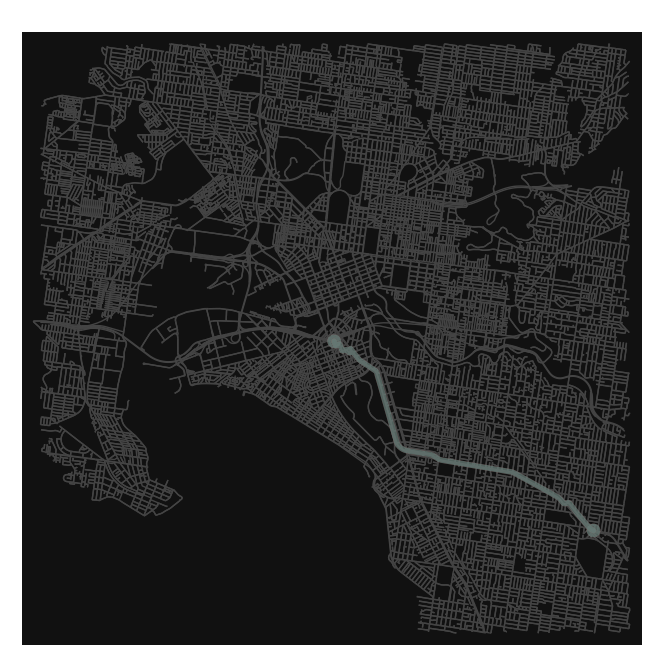

In [77]:
import matplotlib.pyplot as plt

# Sensitivity Sweep over alpha
sweep_rows = []
for alpha_val in [0.0, 0.25, 0.5, 1.0, 2.0]:
    for u, v, k, data in G.edges(keys=True, data=True):
        data["temp_cost"] = data["emg_travel_time"] * (1.0 + alpha_val * data["norm_risk"])
    path_a = nx.dijkstra_path(G, origin_node, dest_node, weight="temp_cost")
    sweep_rows.append(evaluate_route(G, path_a, f"alpha = {alpha_val}"))

print("Pareto Trade-Off Across Risk Penalty Weights (alpha):")
display(pd.DataFrame(sweep_rows))

# Plot Fastest vs. Lower-Risk-Exposure Route
fig, ax = ox.plot_graph_routes(
    G,
    routes=[fastest_dijkstra, lower_risk_path],
    route_colors=["#e63946", "#2a9d8f"],
    route_linewidths=4,
    node_size=0,
    bgcolor="#111111",
    edge_color="#444444",
    show=False,
    close=False
)
ax.set_title("Red: Fastest Route (alpha=0) | Teal: Lower-Risk-Exposure Route (alpha=0.75)", color="white")
plt.show()

## 13. Findings, limitations, and next steps

In [79]:
# Updated project record reflecting Stages 1–12 decisions, findings, and caveats
project_notes = {
    "data_sources": [
        "Victoria Road Crash Relational Dataset (accident, node, atmospheric_cond, road_surface_cond, person, vehicle)",
        "OpenStreetMap (OSMnx) routable drive network & posted speed limits for emergency route optimization"
    ],
    "study_period": f"{model_df['ACCIDENT_DATE'].min().strftime('%Y-%m-%d')} to {model_df['ACCIDENT_DATE'].max().strftime('%Y-%m-%d')}",
    "study_area_definition": (
        "Statewide Victoria road network (prototype baseline for hotspot clustering, severity classification, "
        "and MILP station placement), with a focused 8 km urban road-graph corridor for emergency routing."
    ),
    "column_mapping_confirmed": True,
    "data_quality_issues": [
        "Auxiliary tables (node, atmospheric_cond, road_surface_cond) contained multiple rows per ACCIDENT_NO; deduplicated 1-to-1 before merging to preserve exact crash count (202,554 records).",
        "SPEED_ZONE contained non-numeric/unknown codes (e.g., 777, 999); cleaned to valid posted limits (30–110 km/h) with median imputation.",
        "4 anomalous non-injury records (SEVERITY == 4) excluded so binary target IS_SEVERE cleanly separates Fatal/Serious (1, 2) from Other Injury (3).",
        "Leakage variables (NO_PERSONS_KILLED, NO_PERSONS_INJ_2, NO_PERSONS_INJ_3) strictly excluded from model predictors."
    ],
    "analysis_findings": [
        f"Modelling dataset comprises {len(model_df):,} valid injury crashes; severe crash share (IS_SEVERE=1) is {model_df['IS_SEVERE'].mean():.1%}.",
        "Spatial Clustering: Haversine DBSCAN (250m radius) isolated dense urban crash blackspots, while severity-weighted K-Means (3x weight on fatal/serious) established baseline spatial centroids.",
        "Severity Classification: Evaluated Logistic Regression (baseline) vs. tree ensembles (Random Forest & HistGradientBoosting) using a chronological 80/20 temporal split and balanced class weights; speed zone, accident type, road geometry, and urban context emerged as top severity drivers.",
        "Ambulance Station Optimization (Stage 11): Formulated both Uncapacitated P-Median and Capacitated Facility Location (CFLP) MILP models via SciPy; CFLP prevents single-hub overload while maximizing demand coverage within a 10-minute response threshold.",
        "Emergency Route Optimization (Stage 12): Verified exact optimality between Dijkstra and Admissible A* (Haversine / v_max heuristic) on OSMnx travel times, and mapped the Pareto trade-off between response time and historical crash-density exposure across penalty weights (alpha)."
    ],
    "limitations": [
        "Crowdsourced or police-reported records may under-report minor crashes or vary in spatial precision.",
        "Crash-only records lack traffic volume (AADT) denominators, so edge risk reflects historical crash density rather than true per-vehicle crash probability.",
        "Historical road risk and static OSM speed limits do not capture real-time traffic congestion, weather disruptions, or active road closures.",
        "Candidate ambulance sites were derived from high-volume arterial hubs rather than verified municipal land parcels or existing EMS depots."
    ],
    "next_steps": [
        "Ingest Nairobi-specific crash records (e.g., NTSA / Ma3Route / crowdsourced feeds) and validate local coordinate accuracy.",
        "Replace proxy arterial hubs with verified Nairobi hospitals, fire stations, and St. John / Red Cross ambulance dispatch depots.",
        "Integrate live traffic speed APIs (e.g., Google Routes, HERE, or TomTom) for dynamic time-of-day routing.",
        "Package spatial blackspots, station scenarios, and route trade-offs into an interactive decision-support dashboard."
    ],
}

import pprint
pprint.pprint(project_notes, width=110, sort_dicts=False)

{'data_sources': ['Victoria Road Crash Relational Dataset (accident, node, atmospheric_cond, '
                  'road_surface_cond, person, vehicle)',
                  'OpenStreetMap (OSMnx) routable drive network & posted speed limits for emergency route '
                  'optimization'],
 'study_period': '2012-01-01 to 2026-03-28',
 'study_area_definition': 'Statewide Victoria road network (prototype baseline for hotspot clustering, '
                          'severity classification, and MILP station placement), with a focused 8 km urban '
                          'road-graph corridor for emergency routing.',
 'column_mapping_confirmed': True,
 'data_quality_issues': ['Auxiliary tables (node, atmospheric_cond, road_surface_cond) contained multiple '
                         'rows per ACCIDENT_NO; deduplicated 1-to-1 before merging to preserve exact crash '
                         'count (202,554 records).',
                         'SPEED_ZONE contained non-numeric/unknown co

## 14. Export a cleaned analysis dataset

After cleaning and validating the dataset, save a separate processed copy. Keep raw source files unchanged and record every transformation.


In [80]:
from pathlib import Path
from datetime import datetime
import json

# Define a dedicated output directory separate from raw data
OUTPUT_DIR = Path("data/processed")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Export cleaned & validated analysis dataset
processed_file = OUTPUT_DIR / "crashes_cleaned.csv"
model_df.to_csv(processed_file, index=False)

# Record every transformation & save reproducibility metadata
transformation_log = {
    "exported_at": datetime.now().isoformat(),
    "output_file": str(processed_file.resolve()),
    "row_count": int(len(model_df)),
    "column_count": int(model_df.shape[1]),
    "columns": list(model_df.columns),
    "transformations_applied": [
        "1-to-1 deduplication and left merge of node (LATITUDE, LONGITUDE, LGA_NAME, DEG_URBAN_NAME), atmospheric_cond, and road_surface_cond onto accident table on ACCIDENT_NO.",
        "Filtered out 4 non-injury anomaly records (SEVERITY == 4) to retain valid injury crashes (SEVERITY in [1, 2, 3]).",
        "Created binary severity target IS_SEVERE (1 = Fatal or Serious Injury, 0 = Other Injury).",
        "Extracted temporal features: HOUR, MONTH, and IS_WEEKEND from ACCIDENT_TIME and ACCIDENT_DATE.",
        "Cleaned SPEED_ZONE into SPEED_ZONE_CLEAN by replacing non-standard codes (outside 30–110 km/h) with NaN.",
        "Engineered binary context indicators: IS_INTERSECTION and IS_RAINING."
    ],
    "project_notes": project_notes
}

log_file = OUTPUT_DIR / "crashes_cleaned_metadata.json"
with open(log_file, "w") as f:
    json.dump(transformation_log, f, indent=2, default=str)

# Verify export integrity
assert processed_file.exists() and processed_file.stat().st_size > 0, "Export failed!"
print(f"Saved dataset ({len(model_df):,} rows, {model_df.shape[1]} cols): {processed_file.resolve()}")
print(f"Saved transformation log: {log_file.resolve()}")

Saved dataset (202,550 rows, 46 cols): /content/data/processed/crashes_cleaned.csv
Saved transformation log: /content/data/processed/crashes_cleaned_metadata.json


In [81]:
import joblib
import shutil
from pathlib import Path
from google.colab import files

# Create a dedicated directory for exported models
MODEL_DIR = Path("models_export")
MODEL_DIR.mkdir(parents=True, exist_ok=True)


# Note: If you ran the dictionary loop in Stage 5, ensure your fitted pipelines are stored

if "fitted_models" in globals():
    for name, pipe in fitted_models.items():
        clean_name = name.lower().replace(" ", "_")
        joblib.dump(pipe, MODEL_DIR / f"{clean_name}_pipeline.joblib")

# Fallback if you used the individual pipeline variable names from earlier cells
for var_name in ["log_reg_pipe", "hgb_pipe", "kmeans"]:
    if var_name in globals():
        joblib.dump(globals()[var_name], MODEL_DIR / f"{var_name}.joblib")

if "comparison_df" in globals():
    comparison_df.to_csv(MODEL_DIR / "station_optimization_scenarios.csv", index=False)

if "route_comparison" in globals():
    route_comparison.to_csv(MODEL_DIR / "route_optimization_comparison.csv", index=False)

# Zip the directory and download to your local machine
zip_path = shutil.make_archive("emergency_response_models", "zip", MODEL_DIR)
print(f"Created archive: {zip_path}")
files.download(zip_path)

Created archive: /content/emergency_response_models.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [82]:
import json
import shutil
from datetime import datetime
from pathlib import Path
import joblib
from google.colab import files

# Create a clean bundle directory
BUNDLE_DIR = Path("emergency_analytics_complete_bundle")
if BUNDLE_DIR.exists():
    shutil.rmtree(BUNDLE_DIR)

MODELS_SUBDIR = BUNDLE_DIR / "models"
DATA_SUBDIR = BUNDLE_DIR / "data"
MODELS_SUBDIR.mkdir(parents=True)
DATA_SUBDIR.mkdir(parents=True)

saved_items = []

# Save all trained models (.joblib)
model_registry = {
    "obj1_hotspot_dbscan.joblib": globals().get("dbscan_model"),
    "obj2_accident_occurrence_model.joblib": globals().get("occurrence_model"),
    "obj3_best_severity_pipeline.joblib": globals().get("best_severity_pipe"),
}

# Also save all individual severity classifiers (LogisticRegression, RandomForest, etc.)
if "fitted_severity_models" in globals():
    for name, pipe in fitted_severity_models.items():
        clean_name = name.lower().replace(" ", "_")
        model_registry[f"obj3_severity_{clean_name}.joblib"] = pipe

for filename, obj in model_registry.items():
    if obj is not None:
        joblib.dump(obj, MODELS_SUBDIR / filename)
        saved_items.append(f"models/{filename}")

# Save all cleaned & output datasets (.csv)
dataset_registry = {
    "crashes_cleaned_master.csv": globals().get("model_df"),
    "crashes_geocoded_scored.csv": globals().get("geo_valid"),
    "obj1_validated_hotspots.csv": globals().get("hotspots_df"),
    "obj2_spatiotemporal_panel_test.csv": globals().get("test_occ"),
    "obj4_demand_zones.csv": globals().get("demand_df"),
    "obj4_candidate_stations.csv": globals().get("candidate_df"),
    "obj4_station_optimization_scenarios.csv": globals().get("station_scenarios_df"),
    "obj5_emergency_route_comparison.csv": globals().get("route_comparison_df"),
}

for filename, df_obj in dataset_registry.items():
    if df_obj is not None:
        df_obj.to_csv(DATA_SUBDIR / filename, index=False)
        saved_items.append(f"data/{filename} ({len(df_obj):,} rows)")

# Save project notes & manifest
manifest = {
    "exported_at": datetime.now().isoformat(),
    "contents": saved_items,
    "project_notes": globals().get("project_notes", {})
}
with open(BUNDLE_DIR / "manifest_and_notes.json", "w") as f:
    json.dump(manifest, f, indent=2, default=str)

# Zip everything and trigger browser download
zip_file = shutil.make_archive("emergency_analytics_complete_bundle", "zip", BUNDLE_DIR)
print(f"Packaged {len(saved_items)} files into {zip_file}:")
for item in saved_items:
    print("  -", item)

files.download(zip_file)

Packaged 4 files into /content/emergency_analytics_complete_bundle.zip:
  - data/crashes_cleaned_master.csv (202,550 rows)
  - data/crashes_geocoded_scored.csv (201,275 rows)
  - data/obj4_demand_zones.csv (60 rows)
  - data/obj4_candidate_stations.csv (20 rows)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [85]:
import shutil
from pathlib import Path
import joblib
from sklearn.base import BaseEstimator
from google.colab import files

# 1. Create a clean directory strictly for model files
MODELS_DIR = Path("all_trained_models")
if MODELS_DIR.exists():
    shutil.rmtree(MODELS_DIR)
MODELS_DIR.mkdir(parents=True)

exported = []

# 2. Check named model objects from Objectives 1–3
named_models = {
    "obj1_hotspot_dbscan.joblib": globals().get("dbscan_model"),
    "obj1_ambulance_kmeans.joblib": globals().get("kmeans"),
    "obj2_accident_occurrence_model.joblib": globals().get("occurrence_model") or globals().get("occ_model"),
    "obj3_best_severity_pipeline.joblib": globals().get("best_severity_pipe"),
    "obj3_log_reg_pipeline.joblib": globals().get("log_reg_pipe"),
    "obj3_hgb_pipeline.joblib": globals().get("hgb_pipe"),
}

for fname, model_obj in named_models.items():
    if model_obj is not None:
        joblib.dump(model_obj, MODELS_DIR / fname)
        exported.append(fname)

# 3. Export all models inside dictionary containers (e.g., fitted_severity_models / fitted_models)
for dict_name in ["fitted_severity_models", "fitted_models"]:
    model_dict = globals().get(dict_name)
    if isinstance(model_dict, dict):
        for name, pipe in model_dict.items():
            clean_name = name.lower().replace(" ", "_")
            fname = f"obj3_severity_{clean_name}.joblib"
            if fname not in exported:
                joblib.dump(pipe, MODELS_DIR / fname)
                exported.append(fname)

# 4. Also save the Stage 12 OSMnx road graph if built in memory (contains routing weights)
if "G" in globals() and globals()["G"] is not None:
    import osmnx as ox
    ox.save_graphml(globals()["G"], filepath=MODELS_DIR / "obj5_routable_risk_graph.graphml")
    exported.append("obj5_routable_risk_graph.graphml")

# 5. Zip and trigger browser download
if not exported:
    print("No trained models found in memory. Run the model training blocks (Blocks 2–5) first, then re-run this cell.")
else:
    zip_path = shutil.make_archive("all_trained_models", "zip", MODELS_DIR)
    print(f"Exported {len(exported)} model artifact(s) into {zip_path}:")
    for f in exported:
        print("  -", f)
    files.download(zip_path)

Exported 4 model artifact(s) into /content/all_trained_models.zip:
  - obj1_ambulance_kmeans.joblib
  - obj3_log_reg_pipeline.joblib
  - obj3_hgb_pipeline.joblib
  - obj5_routable_risk_graph.graphml


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>